In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
import os
import gc
import json
import random
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import cv2
import nibabel as nib
import tensorflow as tf

from scipy.ndimage import binary_fill_holes
from scipy.stats import pearsonr


SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass


print("TensorFlow:", tf.__version__)
print("Seed:", SEED)
print("GPU(s):", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
Seed: 42
GPU(s): [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
PROJECT_DIR = Path(
    "/content/drive/MyDrive/CAMUS_FINAL"
)

PHASE1F_DIR = (
    PROJECT_DIR /
    "phase1_segmentation" /
    "phase1F_final_model"
)

PHASE2_DIR = (
    PROJECT_DIR /
    "phase2_quantitative"
)

P2A_DIR = (
    PHASE2_DIR /
    "phase2A_measurement_method"
)

P2B_DIR = (
    PHASE2_DIR /
    "phase2B_final_evaluation"
)

P2B_CONFIG_DIR = P2B_DIR / "configs"
P2B_TABLE_DIR = P2B_DIR / "tables"
P2B_PLOT_DIR = P2B_DIR / "plots"


for folder in [
    P2B_CONFIG_DIR,
    P2B_TABLE_DIR,
    P2B_PLOT_DIR
]:
    folder.mkdir(
        parents=True,
        exist_ok=True
    )


print("Phase 2B directory:")
print(P2B_DIR)

print("\n✓ Phase 2B folders ready.")

Phase 2B directory:
/content/drive/MyDrive/CAMUS_FINAL/phase2_quantitative/phase2B_final_evaluation

✓ Phase 2B folders ready.


In [ ]:
MODEL_POINTER_PATH = (
    PHASE1F_DIR /
    "configs" /
    "phase2_segmentation_model_pointer.json"
)


assert MODEL_POINTER_PATH.exists()


with open(
    MODEL_POINTER_PATH,
    "r"
) as f:
    model_pointer = json.load(f)


FINAL_MODEL_PATH = Path(
    model_pointer["model_path"]
)

EXPECTED_MODEL_SHA256 = (
    model_pointer["sha256"]
)


assert FINAL_MODEL_PATH.exists()
assert model_pointer["frozen"] is True


print("=" * 70)
print("FROZEN SEGMENTATION MODEL")
print("=" * 70)

print("\nModel:")
print(FINAL_MODEL_PATH)

print("\nFrozen:", model_pointer["frozen"])

FROZEN SEGMENTATION MODEL

Model:
/content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1F_final_model/models/final_lv_segmentation_model.keras

Frozen: True


In [ ]:
P2A_DECISION_PATH = (
    P2A_DIR /
    "configs" /
    "phase2A_geometry_method_decision.json"
)

P2A_DEVELOPMENT_PATH = (
    P2A_DIR /
    "configs" /
    "phase2A_development_record.json"
)


assert P2A_DECISION_PATH.exists()
assert P2A_DEVELOPMENT_PATH.exists()


with open(
    P2A_DECISION_PATH,
    "r"
) as f:
    geometry_decision = json.load(f)


with open(
    P2A_DEVELOPMENT_PATH,
    "r"
) as f:
    phase2a_record = json.load(f)


assert (
    geometry_decision[
        "status"
    ]
    == "FROZEN"
)

assert (
    geometry_decision[
        "selected_long_axis_method"
    ]
    == "PCA_major_axis"
)

assert (
    geometry_decision[
        "test_data_used_for_method_selection"
    ]
    is False
)

assert (
    phase2a_record[
        "frozen_before_test_quantitative_evaluation"
    ]
    is True
)


print("=" * 70)
print("PHASE 2A METHOD VERIFIED")
print("=" * 70)

print("\nLong-axis       : PCA major axis")
print("Volume          : Single-plane area-length")
print("Selection data  : Validation")
print("Test selection  : No")

print(
    "\n✓ Quantitative methodology was "
    "frozen before this evaluation."
)

PHASE 2A METHOD VERIFIED

Long-axis       : PCA major axis
Volume          : Single-plane area-length
Selection data  : Validation
Test selection  : No

✓ Quantitative methodology was frozen before this evaluation.


In [ ]:
def sha256_file(file_path):

    sha = hashlib.sha256()

    with open(
        file_path,
        "rb"
    ) as f:

        while True:

            chunk = f.read(
                1024 * 1024
            )

            if not chunk:
                break

            sha.update(chunk)

    return sha.hexdigest()


CURRENT_MODEL_SHA256 = (
    sha256_file(
        FINAL_MODEL_PATH
    )
)


assert (
    CURRENT_MODEL_SHA256
    ==
    EXPECTED_MODEL_SHA256
)


print("=" * 70)
print("MODEL INTEGRITY CHECK")
print("=" * 70)

print("\nSHA-256 matches frozen model:", True)

print(
    "\n✓ Phase 2B is using exactly "
    "the Phase 1F model."
)

MODEL INTEGRITY CHECK

SHA-256 matches frozen model: True

✓ Phase 2B is using exactly the Phase 1F model.


In [ ]:
SPLIT_PATH = (
    PROJECT_DIR /
    "splits" /
    "patient_split_seed42.json"
)


with open(
    SPLIT_PATH,
    "r"
) as f:
    patient_split = json.load(f)


train_ids = patient_split.get(
    "train_ids",
    patient_split.get("train")
)

val_ids = patient_split.get(
    "val_ids",
    patient_split.get(
        "validation",
        patient_split.get("val")
    )
)

test_ids = patient_split.get(
    "test_ids",
    patient_split.get("test")
)


assert len(train_ids) == 400
assert len(val_ids) == 50
assert len(test_ids) == 50


assert set(train_ids).isdisjoint(
    val_ids
)

assert set(train_ids).isdisjoint(
    test_ids
)

assert set(val_ids).isdisjoint(
    test_ids
)


print("Train      :", len(train_ids))
print("Validation :", len(val_ids))
print("Test       :", len(test_ids))

print("\n✓ No patient-level split overlap.")

Train      : 400
Validation : 50
Test       : 50

✓ No patient-level split overlap.


In [ ]:
import zipfile

OUTER_ZIP_PATH = Path(
    "/content/drive/MyDrive/download.zip"
)

OUTER_EXTRACT_DIR = Path(
    "/content/camus_data"
)

INNER_ARCHIVE_PATH = (
    OUTER_EXTRACT_DIR /
    "download"
)

INNER_EXTRACT_DIR = Path(
    "/content/camus_data_final"
)

DATASET_PATH = (
    INNER_EXTRACT_DIR /
    "database_nifti"
)


if not DATASET_PATH.exists():

    assert OUTER_ZIP_PATH.exists(), (
        f"Archive not found: {OUTER_ZIP_PATH}"
    )

    if not INNER_ARCHIVE_PATH.exists():

        print("Extracting outer archive...")

        OUTER_EXTRACT_DIR.mkdir(
            parents=True,
            exist_ok=True
        )

        with zipfile.ZipFile(
            OUTER_ZIP_PATH,
            "r"
        ) as archive:

            archive.extractall(
                OUTER_EXTRACT_DIR
            )

        print("✓ Outer archive extracted.")


    print("Extracting CAMUS archive...")

    INNER_EXTRACT_DIR.mkdir(
        parents=True,
        exist_ok=True
    )

    with zipfile.ZipFile(
        INNER_ARCHIVE_PATH,
        "r"
    ) as archive:

        archive.extractall(
            INNER_EXTRACT_DIR
        )


assert DATASET_PATH.exists()

print("\n✓ CAMUS dataset ready:")
print(DATASET_PATH)

Extracting outer archive...
✓ Outer archive extracted.
Extracting CAMUS archive...

✓ CAMUS dataset ready:
/content/camus_data_final/database_nifti


In [ ]:
def parse_info_cfg(cfg_path):

    info = {}

    with open(
        cfg_path,
        "r",
        encoding="utf-8"
    ) as f:

        for raw in f:

            line = raw.strip()

            if (
                not line
                or line.startswith("#")
                or ":" not in line
            ):
                continue

            key, value = line.split(
                ":",
                1
            )

            key = key.strip()
            value = value.strip()

            try:
                value = int(value)

            except ValueError:

                try:
                    value = float(value)

                except ValueError:
                    pass

            info[key] = value

    return info


def load_nifti_2d(file_path):

    nii = nib.load(
        str(file_path)
    )

    data = np.asarray(
        nii.get_fdata()
    )

    if (
        data.ndim == 3
        and data.shape[-1] == 1
    ):
        data = data[:, :, 0]

    if data.ndim != 2:

        raise ValueError(
            f"Expected 2D NIfTI, got {data.shape}"
        )


    spacing = tuple(
        float(x)
        for x in
        nii.header.get_zooms()[:2]
    )


    return data, spacing


def load_patient_data(patient_id):

    patient_dir = (
        DATASET_PATH /
        patient_id
    )

    clinical = parse_info_cfg(
        patient_dir /
        "Info_4CH.cfg"
    )


    patient = {

        "patient_id":
            patient_id,

        "clinical":
            clinical
    }


    for phase in ["ED", "ES"]:

        image, spacing = (
            load_nifti_2d(
                patient_dir /
                f"{patient_id}_4CH_{phase}.nii.gz"
            )
        )

        gt, gt_spacing = (
            load_nifti_2d(
                patient_dir /
                f"{patient_id}_4CH_{phase}_gt.nii.gz"
            )
        )


        assert np.allclose(
            spacing,
            gt_spacing
        )


        patient[phase] = {

            "image":
                image.astype(
                    np.float32
                ),

            "mask":
                (gt == 1),

            "spacing":
                spacing,

            "original_shape":
                image.shape
        }


    return patient


print("✓ CAMUS loader ready.")

✓ CAMUS loader ready.


In [ ]:
def preprocess_for_segmentation(
    image,
    target_size=256
):

    image = np.asarray(
        image,
        dtype=np.float32
    )

    original_h, original_w = (
        image.shape
    )


    resized = cv2.resize(
        image,
        (
            target_size,
            target_size
        ),
        interpolation=cv2.INTER_LINEAR
    )


    minimum = float(
        resized.min()
    )

    maximum = float(
        resized.max()
    )


    if maximum > minimum:

        normalized = (
            resized - minimum
        ) / (
            maximum - minimum
        )

    else:

        normalized = (
            np.zeros_like(
                resized
            )
        )


    scale_x = (
        original_w /
        target_size
    )

    scale_y = (
        original_h /
        target_size
    )


    return (
        normalized.astype(
            np.float32
        ),
        (
            scale_x,
            scale_y
        )
    )


def preprocess_mask(
    mask,
    target_size=256
):

    resized = cv2.resize(
        np.asarray(mask).astype(
            np.uint8
        ),
        (
            target_size,
            target_size
        ),
        interpolation=cv2.INTER_NEAREST
    )

    return resized > 0


def effective_spacing(
    native_spacing,
    scale_factors
):

    spacing_x, spacing_y = map(
        float,
        native_spacing
    )

    scale_x, scale_y = map(
        float,
        scale_factors
    )


    return (
        spacing_x * scale_x,
        spacing_y * scale_y
    )


print("✓ Frozen preprocessing ready.")

✓ Frozen preprocessing ready.


In [ ]:
def keep_largest_component(mask):

    mask_uint8 = (
        np.asarray(mask)
        .astype(np.uint8)
    )


    if mask_uint8.sum() == 0:

        return np.zeros_like(
            mask_uint8,
            dtype=bool
        )


    n_labels, labels, stats, _ = (
        cv2.connectedComponentsWithStats(
            mask_uint8,
            connectivity=8
        )
    )


    if n_labels <= 1:

        return np.zeros_like(
            mask_uint8,
            dtype=bool
        )


    largest_label = (
        1
        +
        np.argmax(
            stats[
                1:,
                cv2.CC_STAT_AREA
            ]
        )
    )


    return labels == largest_label


def postprocess_prediction(
    probability_mask,
    threshold=0.50
):

    binary_mask = (
        probability_mask
        >=
        threshold
    )


    largest = (
        keep_largest_component(
            binary_mask
        )
    )


    filled = (
        binary_fill_holes(
            largest
        )
    )


    return np.asarray(
        filled
    ).astype(bool)


print("✓ Frozen postprocessing ready.")

✓ Frozen postprocessing ready.


In [ ]:
def mask_area_mm2(
    mask,
    spacing
):

    mask = np.asarray(
        mask
    ).astype(bool)

    spacing_x, spacing_y = map(
        float,
        spacing
    )


    return float(
        mask.sum()
        *
        spacing_x
        *
        spacing_y
    )


def mask_points_mm(
    mask,
    spacing
):

    rows, cols = np.where(
        np.asarray(mask).astype(bool)
    )


    spacing_x, spacing_y = map(
        float,
        spacing
    )


    x_mm = (
        cols.astype(np.float64)
        *
        spacing_x
    )

    y_mm = (
        rows.astype(np.float64)
        *
        spacing_y
    )


    return np.column_stack([
        x_mm,
        y_mm
    ])


def pca_major_axis_mm(
    mask,
    spacing
):

    points = mask_points_mm(
        mask,
        spacing
    )


    if len(points) < 2:
        return np.nan


    centered = (
        points
        -
        points.mean(axis=0)
    )


    covariance = np.cov(
        centered,
        rowvar=False
    )


    eigenvalues, eigenvectors = (
        np.linalg.eigh(
            covariance
        )
    )


    principal_axis = (
        eigenvectors[
            :,
            np.argmax(
                eigenvalues
            )
        ]
    )


    projections = (
        centered
        @
        principal_axis
    )


    return float(
        projections.max()
        -
        projections.min()
    )


def area_length_volume_ml(
    area_mm2,
    length_mm
):

    if (
        not np.isfinite(area_mm2)
        or not np.isfinite(length_mm)
        or area_mm2 <= 0
        or length_mm <= 0
    ):
        return np.nan


    area_cm2 = (
        area_mm2 /
        100.0
    )

    length_cm = (
        length_mm /
        10.0
    )


    return float(

        (
            8.0
            /
            (
                3.0
                *
                np.pi
            )
        )

        *

        (
            area_cm2 ** 2
        )

        /

        length_cm
    )


print("✓ Frozen PCA area-length geometry ready.")

✓ Frozen PCA area-length geometry ready.


In [ ]:
tf.keras.backend.clear_session()
gc.collect()


frozen_segmentation_model = (
    tf.keras.models.load_model(
        FINAL_MODEL_PATH,
        compile=False
    )
)


assert (
    frozen_segmentation_model.count_params()
    ==
    7_759_521
)

assert (
    frozen_segmentation_model.input_shape
    ==
    (None, 256, 256, 1)
)


print("=" * 70)
print("FROZEN MODEL LOADED")
print("=" * 70)

print(
    "\nParameters:",
    f"{frozen_segmentation_model.count_params():,}"
)

print(
    "Input:",
    frozen_segmentation_model.input_shape
)

print("\n✓ Ready for locked evaluation.")

FROZEN MODEL LOADED

Parameters: 7,759,521
Input: (None, 256, 256, 1)

✓ Ready for locked evaluation.


In [ ]:
P2B_PROTOCOL_PATH = (
    P2B_CONFIG_DIR /
    "phase2B_locked_evaluation_protocol.json"
)


phase2b_protocol = {

    "status":
        "LOCKED_BEFORE_TEST_INFERENCE",

    "partition":
        "test",

    "n_patients":
        50,

    "n_frames":
        100,

    "phases": [
        "ED",
        "ES"
    ],

    "segmentation_model":
        str(FINAL_MODEL_PATH),

    "segmentation_model_sha256":
        EXPECTED_MODEL_SHA256,

    "segmentation_resolution":
        256,

    "segmentation_threshold":
        0.50,

    "segmentation_postprocessing": [
        "largest connected component",
        "binary hole filling"
    ],

    "long_axis_method":
        "PCA major axis",

    "volume_method":
        "single-plane area-length",

    "volume_equation":
        "V = (8/(3*pi)) * A^2/L",

    "physical_spacing":
        (
            "Original NIfTI pixel spacing adjusted "
            "for x/y stretch-resize scale factors."
        ),

    "outputs": [
        "ED area",
        "ES area",
        "ED length",
        "ES length",
        "EDV",
        "ESV",
        "SV",
        "EF"
    ],

    "reference_EF_source":
        "CAMUS Info_4CH.cfg EF",

    "post_test_changes_allowed":
        False,

    "prohibited_post_test_actions": [
        "segmentation retraining",
        "threshold tuning",
        "postprocessing tuning",
        "PCA/Feret reselection",
        "area-bias correction",
        "EF calibration",
        "geometry-method modification"
    ],

    "test_partition_limitation":
        (
            "The 50-patient partition was held out from "
            "the clean Phase 1A-1D and Phase 2A method-selection "
            "processes, but had historical pilot exposure and is "
            "therefore not claimed to be a pristine external test set."
        )
}


with open(
    P2B_PROTOCOL_PATH,
    "w"
) as f:

    json.dump(
        phase2b_protocol,
        f,
        indent=2
    )


print("=" * 70)
print("PHASE 2B TEST PROTOCOL LOCKED")
print("=" * 70)

print("\nPatients        : 50")
print("Frames          : 100")
print("Geometry        : PCA major axis")
print("Volume          : Single-plane area-length")
print("Threshold       : 0.50")
print("Post-test tuning: PROHIBITED")

print("\n✓ Protocol saved before inference.")

PHASE 2B TEST PROTOCOL LOCKED

Patients        : 50
Frames          : 100
Geometry        : PCA major axis
Volume          : Single-plane area-length
Threshold       : 0.50
Post-test tuning: PROHIBITED

✓ Protocol saved before inference.


In [ ]:
test_measurement_records = []


for index, pid in enumerate(
    test_ids,
    start=1
):

    patient_data = (
        load_patient_data(pid)
    )


    record = {

        "patient_id":
            pid,

        "reference_EF_pct":
            float(
                patient_data[
                    "clinical"
                ]["EF"]
            ),

        "image_quality":
            patient_data[
                "clinical"
            ]["ImageQuality"],

        "age":
            patient_data[
                "clinical"
            ]["Age"],

        "sex":
            patient_data[
                "clinical"
            ]["Sex"]
    }


    for phase in ["ED", "ES"]:

        phase_data = (
            patient_data[phase]
        )


        image = (
            phase_data["image"]
        )

        native_gt_mask = (
            phase_data["mask"]
        )

        native_spacing = (
            phase_data["spacing"]
        )


        # ========================================================
        # Frozen preprocessing
        # ========================================================

        processed_image, scale_factors = (
            preprocess_for_segmentation(
                image,
                target_size=256
            )
        )


        resized_gt_mask = (
            preprocess_mask(
                native_gt_mask,
                target_size=256
            )
        )


        resized_spacing = (
            effective_spacing(
                native_spacing,
                scale_factors
            )
        )


        # ========================================================
        # Frozen segmentation
        # ========================================================

        model_input = (
            processed_image[
                None,
                ...,
                None
            ]
        )


        probability = (
            frozen_segmentation_model(
                model_input,
                training=False
            )
            .numpy()[0, :, :, 0]
        )


        predicted_mask = (
            postprocess_prediction(
                probability,
                threshold=0.50
            )
        )


        # ========================================================
        # Ground-truth-mask geometry
        # ========================================================

        gt_area = mask_area_mm2(
            resized_gt_mask,
            resized_spacing
        )


        gt_length = pca_major_axis_mm(
            resized_gt_mask,
            resized_spacing
        )


        gt_volume = area_length_volume_ml(
            gt_area,
            gt_length
        )


        # ========================================================
        # Predicted-mask geometry
        # ========================================================

        pred_area = mask_area_mm2(
            predicted_mask,
            resized_spacing
        )


        pred_length = pca_major_axis_mm(
            predicted_mask,
            resized_spacing
        )


        pred_volume = area_length_volume_ml(
            pred_area,
            pred_length
        )


        record[
            f"{phase}_GT_area_mm2"
        ] = gt_area

        record[
            f"{phase}_PRED_area_mm2"
        ] = pred_area

        record[
            f"{phase}_GT_length_mm"
        ] = gt_length

        record[
            f"{phase}_PRED_length_mm"
        ] = pred_length

        record[
            f"{phase}_GT_volume_ml"
        ] = gt_volume

        record[
            f"{phase}_PRED_volume_ml"
        ] = pred_volume


    # ============================================================
    # GT-mask derived quantities
    # ============================================================

    record["GT_SV_ml"] = (
        record["ED_GT_volume_ml"]
        -
        record["ES_GT_volume_ml"]
    )


    record["GT_EF_pct"] = (
        record["GT_SV_ml"]
        /
        record["ED_GT_volume_ml"]
        *
        100.0
    )


    # ============================================================
    # Predicted-mask derived quantities
    # ============================================================

    record["PRED_SV_ml"] = (
        record["ED_PRED_volume_ml"]
        -
        record["ES_PRED_volume_ml"]
    )


    record["PRED_EF_pct"] = (
        record["PRED_SV_ml"]
        /
        record["ED_PRED_volume_ml"]
        *
        100.0
    )


    test_measurement_records.append(
        record
    )


    if (
        index % 10 == 0
        or index == len(test_ids)
    ):

        print(
            f"Processed "
            f"{index}/{len(test_ids)} "
            f"test patients"
        )


test_measurements_df = pd.DataFrame(
    test_measurement_records
)


assert len(test_measurements_df) == 50


TEST_MEASUREMENTS_PATH = (
    P2B_TABLE_DIR /
    "final_test_quantitative_measurements.csv"
)


test_measurements_df.to_csv(
    TEST_MEASUREMENTS_PATH,
    index=False
)


print("\n" + "=" * 70)
print("LOCKED TEST INFERENCE COMPLETE")
print("=" * 70)

print("\nPatients:", len(test_measurements_df))

print("\nSaved:")
print(TEST_MEASUREMENTS_PATH)

Processed 10/50 test patients
Processed 20/50 test patients
Processed 30/50 test patients
Processed 40/50 test patients
Processed 50/50 test patients

LOCKED TEST INFERENCE COMPLETE

Patients: 50

Saved:
/content/drive/MyDrive/CAMUS_FINAL/phase2_quantitative/phase2B_final_evaluation/tables/final_test_quantitative_measurements.csv


In [ ]:
sanity_checks = {

    "all_GT_EDV_positive":
        bool(
            (
                test_measurements_df[
                    "ED_GT_volume_ml"
                ] > 0
            ).all()
        ),

    "all_GT_ESV_positive":
        bool(
            (
                test_measurements_df[
                    "ES_GT_volume_ml"
                ] > 0
            ).all()
        ),

    "all_PRED_EDV_positive":
        bool(
            (
                test_measurements_df[
                    "ED_PRED_volume_ml"
                ] > 0
            ).all()
        ),

    "all_PRED_ESV_positive":
        bool(
            (
                test_measurements_df[
                    "ES_PRED_volume_ml"
                ] > 0
            ).all()
        ),

    "GT_EF_in_0_100":
        bool(
            test_measurements_df[
                "GT_EF_pct"
            ].between(
                0,
                100
            ).all()
        ),

    "PRED_EF_in_0_100":
        bool(
            test_measurements_df[
                "PRED_EF_pct"
            ].between(
                0,
                100
            ).all()
        ),

    "all_GT_EDV_greater_ESV":
        bool(
            (
                test_measurements_df[
                    "ED_GT_volume_ml"
                ]
                >
                test_measurements_df[
                    "ES_GT_volume_ml"
                ]
            ).all()
        ),

    "all_PRED_EDV_greater_ESV":
        bool(
            (
                test_measurements_df[
                    "ED_PRED_volume_ml"
                ]
                >
                test_measurements_df[
                    "ES_PRED_volume_ml"
                ]
            ).all()
        )
}


print("=" * 70)
print("FINAL QUANTITATIVE SANITY CHECK")
print("=" * 70)


for name, passed in sanity_checks.items():

    print(
        f"{name:30s}: "
        f"{'✓' if passed else '✗'}"
    )


failed_checks = [
    name
    for name, passed
    in sanity_checks.items()
    if not passed
]


print(
    "\nFailed checks:",
    len(failed_checks)
)


if failed_checks:

    print(
        "\nIMPORTANT: Do not modify the pipeline."
    )

    print(
        "We will inspect the affected patients "
        "as final-evaluation failure cases."
    )

FINAL QUANTITATIVE SANITY CHECK
all_GT_EDV_positive           : ✓
all_GT_ESV_positive           : ✓
all_PRED_EDV_positive         : ✓
all_PRED_ESV_positive         : ✓
GT_EF_in_0_100                : ✓
PRED_EF_in_0_100              : ✓
all_GT_EDV_greater_ESV        : ✓
all_PRED_EDV_greater_ESV      : ✓

Failed checks: 0


In [ ]:
def error_summary(
    reference,
    estimate
):

    reference = np.asarray(
        reference,
        dtype=float
    )

    estimate = np.asarray(
        estimate,
        dtype=float
    )


    valid = (
        np.isfinite(reference)
        &
        np.isfinite(estimate)
    )


    reference = reference[valid]
    estimate = estimate[valid]


    error = (
        estimate
        -
        reference
    )


    mae = float(
        np.mean(
            np.abs(error)
        )
    )


    rmse = float(
        np.sqrt(
            np.mean(
                error ** 2
            )
        )
    )


    bias = float(
        np.mean(error)
    )


    if (
        len(reference) > 1
        and np.std(reference) > 0
        and np.std(estimate) > 0
    ):

        correlation = float(
            pearsonr(
                reference,
                estimate
            ).statistic
        )

    else:

        correlation = np.nan


    return {

        "n":
            int(len(reference)),

        "MAE":
            mae,

        "RMSE":
            rmse,

        "bias":
            bias,

        "correlation":
            correlation
    }


print("✓ Evaluation function ready.")

✓ Evaluation function ready.


In [ ]:
measurement_pairs = [

    (
        "ED_area_mm2",
        "ED_GT_area_mm2",
        "ED_PRED_area_mm2"
    ),

    (
        "ES_area_mm2",
        "ES_GT_area_mm2",
        "ES_PRED_area_mm2"
    ),

    (
        "ED_length_mm",
        "ED_GT_length_mm",
        "ED_PRED_length_mm"
    ),

    (
        "ES_length_mm",
        "ES_GT_length_mm",
        "ES_PRED_length_mm"
    ),

    (
        "EDV_ml",
        "ED_GT_volume_ml",
        "ED_PRED_volume_ml"
    ),

    (
        "ESV_ml",
        "ES_GT_volume_ml",
        "ES_PRED_volume_ml"
    ),

    (
        "SV_ml",
        "GT_SV_ml",
        "PRED_SV_ml"
    ),

    (
        "EF_percentage_points",
        "GT_EF_pct",
        "PRED_EF_pct"
    )
]


final_measurement_error_records = []


for (
    quantity,
    gt_column,
    pred_column
) in measurement_pairs:

    stats = error_summary(

        test_measurements_df[
            gt_column
        ],

        test_measurements_df[
            pred_column
        ]
    )


    final_measurement_error_records.append({

        "quantity":
            quantity,

        **stats
    })


final_measurement_error_df = (
    pd.DataFrame(
        final_measurement_error_records
    )
)


display(
    final_measurement_error_df.round(4)
)


FINAL_MEASUREMENT_ERROR_PATH = (
    P2B_TABLE_DIR /
    "final_test_segmentation_to_measurement_error.csv"
)


final_measurement_error_df.to_csv(
    FINAL_MEASUREMENT_ERROR_PATH,
    index=False
)


print("\nSaved:")
print(FINAL_MEASUREMENT_ERROR_PATH)

,quantity,n,MAE,RMSE,bias,correlation
0,ED_area_mm2,50,203.1518,255.3348,-146.0928,0.9417
1,ES_area_mm2,50,179.2046,236.2640,-112.7997,0.9116
2,ED_length_mm,50,2.7934,3.8407,-0.9855,0.9166
3,ES_length_mm,50,3.3978,4.9774,-2.2619,0.8589
4,EDV_ml,50,11.4050,14.6416,-8.2335,0.9182
5,ESV_ml,50,7.1756,9.5907,-4.1211,0.9070
6,SV_ml,50,7.9325,10.4450,-4.1124,0.8761
7,EF_percentage_points,50,5.8940,7.5615,0.1038,0.8474



Saved:
/content/drive/MyDrive/CAMUS_FINAL/phase2_quantitative/phase2B_final_evaluation/tables/final_test_segmentation_to_measurement_error.csv


In [ ]:
reference_ef = (
    test_measurements_df[
        "reference_EF_pct"
    ].to_numpy(dtype=float)
)


gt_geometry_ef = (
    test_measurements_df[
        "GT_EF_pct"
    ].to_numpy(dtype=float)
)


predicted_geometry_ef = (
    test_measurements_df[
        "PRED_EF_pct"
    ].to_numpy(dtype=float)
)


final_ef_decomposition_records = []


comparisons = [

    (
        "Reference EF → GT-mask geometry EF",
        "Geometry/reference disagreement",
        reference_ef,
        gt_geometry_ef
    ),

    (
        "GT-mask geometry EF → predicted-mask EF",
        "Segmentation-induced downstream disagreement",
        gt_geometry_ef,
        predicted_geometry_ef
    ),

    (
        "Reference EF → predicted-mask EF",
        "Total end-to-end disagreement",
        reference_ef,
        predicted_geometry_ef
    )
]


for (
    comparison,
    interpretation,
    reference,
    estimate
) in comparisons:

    stats = error_summary(
        reference,
        estimate
    )


    final_ef_decomposition_records.append({

        "comparison":
            comparison,

        "interpretation":
            interpretation,

        **stats
    })


final_ef_decomposition_df = (
    pd.DataFrame(
        final_ef_decomposition_records
    )
)


display(
    final_ef_decomposition_df.round(4)
)


FINAL_EF_DECOMPOSITION_PATH = (
    P2B_TABLE_DIR /
    "final_test_EF_error_decomposition.csv"
)


final_ef_decomposition_df.to_csv(
    FINAL_EF_DECOMPOSITION_PATH,
    index=False
)


print("\nSaved:")
print(FINAL_EF_DECOMPOSITION_PATH)

,comparison,interpretation,n,MAE,RMSE,bias,correlation
0,Reference EF → GT-mask geometry EF,Geometry/reference disagreement,50,6.6676,9.6954,4.8100,0.7994
1,GT-mask geometry EF → predicted-mask EF,Segmentation-induced downstream disagreement,50,5.8940,7.5615,0.1038,0.8474
2,Reference EF → predicted-mask EF,Total end-to-end disagreement,50,8.1906,11.0241,4.9139,0.7083



Saved:
/content/drive/MyDrive/CAMUS_FINAL/phase2_quantitative/phase2B_final_evaluation/tables/final_test_EF_error_decomposition.csv


In [ ]:
# ================================================================
# PHASE 2B — CELL 20
# RELATIVE QUANTITATIVE ERRORS
# ================================================================

relative_error_records = []


relative_pairs = [

    (
        "ED_area",
        "ED_GT_area_mm2",
        "ED_PRED_area_mm2"
    ),

    (
        "ES_area",
        "ES_GT_area_mm2",
        "ES_PRED_area_mm2"
    ),

    (
        "ED_length",
        "ED_GT_length_mm",
        "ED_PRED_length_mm"
    ),

    (
        "ES_length",
        "ES_GT_length_mm",
        "ES_PRED_length_mm"
    ),

    (
        "EDV",
        "ED_GT_volume_ml",
        "ED_PRED_volume_ml"
    ),

    (
        "ESV",
        "ES_GT_volume_ml",
        "ES_PRED_volume_ml"
    )
]


for (
    quantity,
    gt_column,
    pred_column
) in relative_pairs:

    gt = (
        test_measurements_df[
            gt_column
        ].to_numpy(dtype=float)
    )

    pred = (
        test_measurements_df[
            pred_column
        ].to_numpy(dtype=float)
    )


    relative_error_pct = (
        (pred - gt)
        /
        gt
        *
        100.0
    )


    relative_error_records.append({

        "quantity":
            quantity,

        "relative_MAE_pct":
            float(
                np.mean(
                    np.abs(
                        relative_error_pct
                    )
                )
            ),

        "relative_bias_pct":
            float(
                np.mean(
                    relative_error_pct
                )
            ),

        "median_absolute_relative_error_pct":
            float(
                np.median(
                    np.abs(
                        relative_error_pct
                    )
                )
            ),

        "q75_absolute_relative_error_pct":
            float(
                np.percentile(
                    np.abs(
                        relative_error_pct
                    ),
                    75
                )
            )
    })


relative_error_df = pd.DataFrame(
    relative_error_records
)


display(
    relative_error_df.round(4)
)


RELATIVE_ERROR_PATH = (
    P2B_TABLE_DIR /
    "final_test_relative_measurement_errors.csv"
)


relative_error_df.to_csv(
    RELATIVE_ERROR_PATH,
    index=False
)

,quantity,relative_MAE_pct,relative_bias_pct,median_absolute_relative_error_pct,q75_absolute_relative_error_pct
0,ED_area,6.8817,-4.3253,5.5976,9.6309
1,ES_area,9.4824,-5.0406,7.7022,13.0171
2,ED_length,3.4233,-1.0651,2.6320,5.1051
3,ES_length,5.1209,-3.2663,3.9359,5.9516
4,EDV,11.8762,-7.0275,10.2008,17.4630
5,ESV,15.4781,-6.1185,13.4393,23.2878


In [ ]:
# ================================================================
# PHASE 2B — CELL 21
# BLAND-ALTMAN AGREEMENT STATISTICS
# ================================================================

def bland_altman_stats(
    reference,
    estimate
):

    reference = np.asarray(
        reference,
        dtype=float
    )

    estimate = np.asarray(
        estimate,
        dtype=float
    )


    difference = (
        estimate - reference
    )


    bias = float(
        np.mean(difference)
    )


    sd = float(
        np.std(
            difference,
            ddof=1
        )
    )


    lower_loa = (
        bias
        -
        1.96 * sd
    )

    upper_loa = (
        bias
        +
        1.96 * sd
    )


    return {
        "bias":
            bias,

        "SD_difference":
            sd,

        "lower_95_LOA":
            float(lower_loa),

        "upper_95_LOA":
            float(upper_loa)
    }


agreement_records = []


agreement_pairs = [

    (
        "EDV_GT_vs_PRED",
        "ED_GT_volume_ml",
        "ED_PRED_volume_ml"
    ),

    (
        "ESV_GT_vs_PRED",
        "ES_GT_volume_ml",
        "ES_PRED_volume_ml"
    ),

    (
        "EF_GT_geometry_vs_PRED",
        "GT_EF_pct",
        "PRED_EF_pct"
    ),

    (
        "EF_reference_vs_GT_geometry",
        "reference_EF_pct",
        "GT_EF_pct"
    ),

    (
        "EF_reference_vs_PRED",
        "reference_EF_pct",
        "PRED_EF_pct"
    )
]


for (
    comparison,
    reference_column,
    estimate_column
) in agreement_pairs:

    stats = bland_altman_stats(

        test_measurements_df[
            reference_column
        ],

        test_measurements_df[
            estimate_column
        ]
    )


    agreement_records.append({

        "comparison":
            comparison,

        **stats
    })


agreement_df = pd.DataFrame(
    agreement_records
)


display(
    agreement_df.round(4)
)


AGREEMENT_PATH = (
    P2B_TABLE_DIR /
    "final_test_bland_altman_statistics.csv"
)


agreement_df.to_csv(
    AGREEMENT_PATH,
    index=False
)

,comparison,bias,SD_difference,lower_95_LOA,upper_95_LOA
0,EDV_GT_vs_PRED,-8.2335,12.2302,-32.2046,15.7376
1,ESV_GT_vs_PRED,-4.1211,8.7480,-21.2672,13.0251
2,EF_GT_geometry_vs_PRED,0.1038,7.6375,-14.8657,15.0734
3,EF_reference_vs_GT_geometry,4.8100,8.5036,-11.8571,21.4771
4,EF_reference_vs_PRED,4.9139,9.9686,-14.6246,24.4523


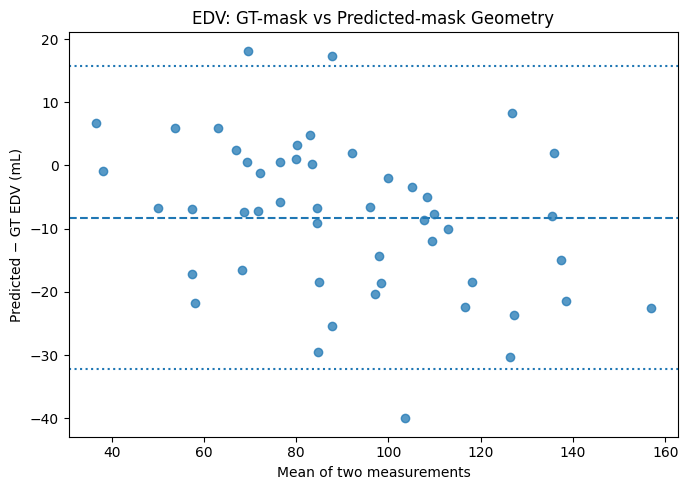

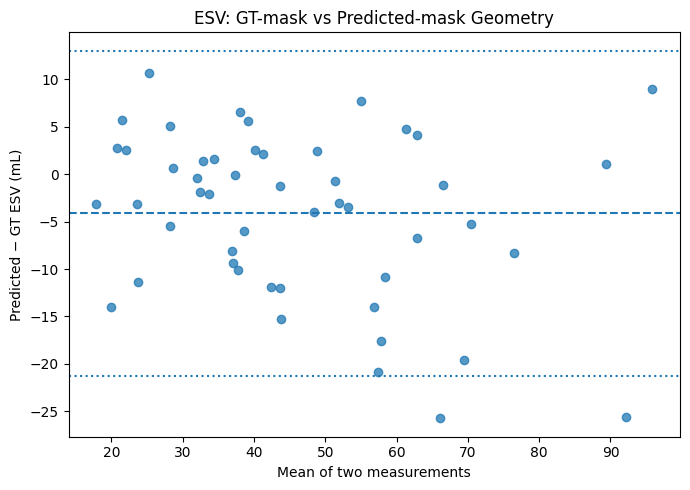

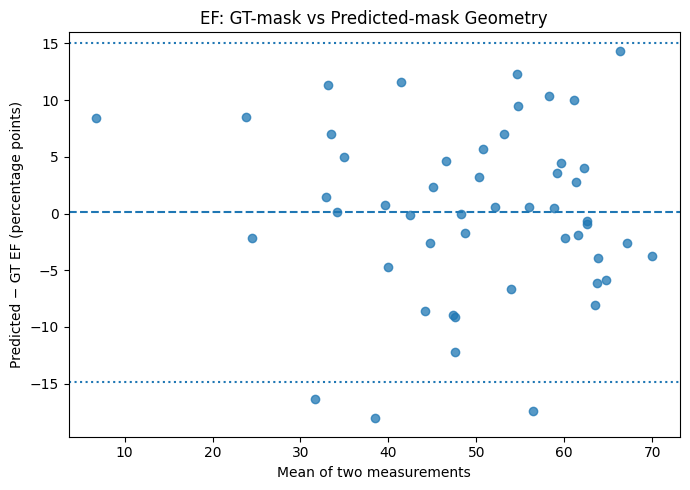

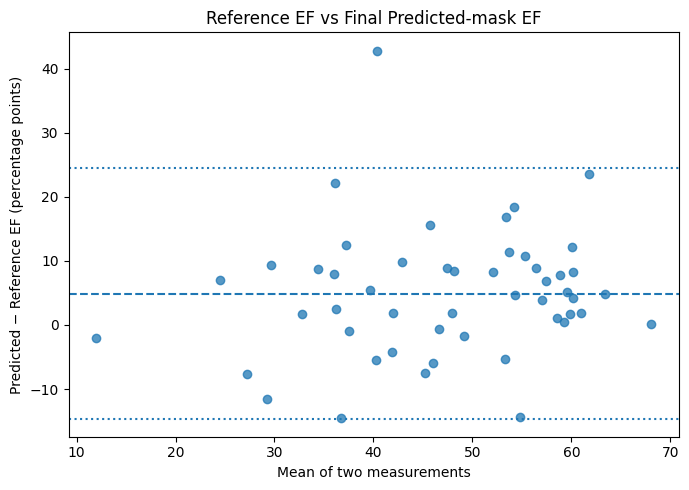

In [ ]:
# ================================================================
# PHASE 2B — CELL 22
# BLAND-ALTMAN PLOTS
# ================================================================

def make_bland_altman_plot(
    reference,
    estimate,
    title,
    ylabel,
    save_path
):

    reference = np.asarray(
        reference,
        dtype=float
    )

    estimate = np.asarray(
        estimate,
        dtype=float
    )


    means = (
        reference + estimate
    ) / 2.0

    differences = (
        estimate - reference
    )


    bias = np.mean(
        differences
    )

    sd = np.std(
        differences,
        ddof=1
    )

    lower = bias - 1.96 * sd
    upper = bias + 1.96 * sd


    plt.figure(
        figsize=(7, 5)
    )

    plt.scatter(
        means,
        differences,
        alpha=0.75
    )

    plt.axhline(
        bias,
        linestyle="--"
    )

    plt.axhline(
        lower,
        linestyle=":"
    )

    plt.axhline(
        upper,
        linestyle=":"
    )

    plt.xlabel(
        "Mean of two measurements"
    )

    plt.ylabel(
        ylabel
    )

    plt.title(
        title
    )

    plt.tight_layout()

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()


make_bland_altman_plot(

    test_measurements_df[
        "ED_GT_volume_ml"
    ],

    test_measurements_df[
        "ED_PRED_volume_ml"
    ],

    "EDV: GT-mask vs Predicted-mask Geometry",

    "Predicted − GT EDV (mL)",

    P2B_PLOT_DIR /
    "bland_altman_EDV.png"
)


make_bland_altman_plot(

    test_measurements_df[
        "ES_GT_volume_ml"
    ],

    test_measurements_df[
        "ES_PRED_volume_ml"
    ],

    "ESV: GT-mask vs Predicted-mask Geometry",

    "Predicted − GT ESV (mL)",

    P2B_PLOT_DIR /
    "bland_altman_ESV.png"
)


make_bland_altman_plot(

    test_measurements_df[
        "GT_EF_pct"
    ],

    test_measurements_df[
        "PRED_EF_pct"
    ],

    "EF: GT-mask vs Predicted-mask Geometry",

    "Predicted − GT EF (percentage points)",

    P2B_PLOT_DIR /
    "bland_altman_EF_GT_vs_PRED.png"
)


make_bland_altman_plot(

    test_measurements_df[
        "reference_EF_pct"
    ],

    test_measurements_df[
        "PRED_EF_pct"
    ],

    "Reference EF vs Final Predicted-mask EF",

    "Predicted − Reference EF (percentage points)",

    P2B_PLOT_DIR /
    "bland_altman_reference_vs_predicted_EF.png"
)

In [ ]:
# ================================================================
# PHASE 2B — CELL 23
# IMAGE-QUALITY SUBGROUP ANALYSIS
# ================================================================

quality_records = []


for quality in sorted(
    test_measurements_df[
        "image_quality"
    ].unique()
):

    subgroup = (
        test_measurements_df[
            test_measurements_df[
                "image_quality"
            ]
            ==
            quality
        ]
    )


    # GT geometry -> predicted geometry EF
    segmentation_stats = (
        error_summary(

            subgroup[
                "GT_EF_pct"
            ],

            subgroup[
                "PRED_EF_pct"
            ]
        )
    )


    # Reference -> predicted EF
    final_stats = (
        error_summary(

            subgroup[
                "reference_EF_pct"
            ],

            subgroup[
                "PRED_EF_pct"
            ]
        )
    )


    quality_records.append({

        "image_quality":
            quality,

        "n":
            len(subgroup),

        "GT_to_PRED_EF_MAE_pp":
            segmentation_stats[
                "MAE"
            ],

        "GT_to_PRED_EF_bias_pp":
            segmentation_stats[
                "bias"
            ],

        "GT_to_PRED_EF_correlation":
            segmentation_stats[
                "correlation"
            ],

        "Reference_to_PRED_EF_MAE_pp":
            final_stats[
                "MAE"
            ],

        "Reference_to_PRED_EF_bias_pp":
            final_stats[
                "bias"
            ],

        "Reference_to_PRED_EF_correlation":
            final_stats[
                "correlation"
            ]
    })


quality_df = pd.DataFrame(
    quality_records
)


display(
    quality_df.round(4)
)


QUALITY_PATH = (
    P2B_TABLE_DIR /
    "final_test_image_quality_subgroups.csv"
)


quality_df.to_csv(
    QUALITY_PATH,
    index=False
)

,image_quality,n,GT_to_PRED_EF_MAE_pp,GT_to_PRED_EF_bias_pp,GT_to_PRED_EF_correlation,Reference_to_PRED_EF_MAE_pp,Reference_to_PRED_EF_bias_pp,Reference_to_PRED_EF_correlation
0,Good,30,5.0287,-1.1799,0.8364,7.3117,5.2960,0.6586
1,Medium,13,6.0277,2.5894,0.7956,9.7344,6.4258,0.6574
2,Poor,7,9.3545,0.9895,0.7222,9.0902,0.4682,0.5091


In [ ]:
# ================================================================
# PHASE 2B — CELL 24
# PATIENT-LEVEL ERROR ANALYSIS
# ================================================================

patient_error_df = (
    test_measurements_df.copy()
)


patient_error_df[
    "GT_to_PRED_EF_error_pp"
] = (

    patient_error_df[
        "PRED_EF_pct"
    ]

    -

    patient_error_df[
        "GT_EF_pct"
    ]
)


patient_error_df[
    "GT_to_PRED_EF_abs_error_pp"
] = np.abs(

    patient_error_df[
        "GT_to_PRED_EF_error_pp"
    ]
)


patient_error_df[
    "Reference_to_PRED_EF_error_pp"
] = (

    patient_error_df[
        "PRED_EF_pct"
    ]

    -

    patient_error_df[
        "reference_EF_pct"
    ]
)


patient_error_df[
    "Reference_to_PRED_EF_abs_error_pp"
] = np.abs(

    patient_error_df[
        "Reference_to_PRED_EF_error_pp"
    ]
)


for phase in ["ED", "ES"]:

    patient_error_df[
        f"{phase}_area_relative_error_pct"
    ] = (

        (
            patient_error_df[
                f"{phase}_PRED_area_mm2"
            ]
            -
            patient_error_df[
                f"{phase}_GT_area_mm2"
            ]
        )

        /

        patient_error_df[
            f"{phase}_GT_area_mm2"
        ]

        *

        100.0
    )


PATIENT_ERROR_PATH = (
    P2B_TABLE_DIR /
    "final_test_patient_level_errors.csv"
)


patient_error_df.to_csv(
    PATIENT_ERROR_PATH,
    index=False
)


print("✓ Patient-level error table saved.")

✓ Patient-level error table saved.


In [ ]:
# ================================================================
# PHASE 2B — CELL 25
# WORST FINAL EVALUATION CASES
# ================================================================

worst_segmentation_ef = (

    patient_error_df
    .sort_values(
        "GT_to_PRED_EF_abs_error_pp",
        ascending=False
    )
    [
        [
            "patient_id",
            "image_quality",
            "reference_EF_pct",
            "GT_EF_pct",
            "PRED_EF_pct",
            "GT_to_PRED_EF_abs_error_pp",
            "ED_area_relative_error_pct",
            "ES_area_relative_error_pct"
        ]
    ]
    .head(10)
)


worst_end_to_end_ef = (

    patient_error_df
    .sort_values(
        "Reference_to_PRED_EF_abs_error_pp",
        ascending=False
    )
    [
        [
            "patient_id",
            "image_quality",
            "reference_EF_pct",
            "GT_EF_pct",
            "PRED_EF_pct",
            "Reference_to_PRED_EF_abs_error_pp",
            "ED_area_relative_error_pct",
            "ES_area_relative_error_pct"
        ]
    ]
    .head(10)
)


print("=" * 70)
print("WORST GT-GEOMETRY → PREDICTED-GEOMETRY EF CASES")
print("=" * 70)

display(
    worst_segmentation_ef.round(3)
)


print("\n" + "=" * 70)
print("WORST REFERENCE → FINAL PREDICTED EF CASES")
print("=" * 70)

display(
    worst_end_to_end_ef.round(3)
)


worst_segmentation_ef.to_csv(

    P2B_TABLE_DIR /
    "worst_10_segmentation_induced_EF_cases.csv",

    index=False
)


worst_end_to_end_ef.to_csv(

    P2B_TABLE_DIR /
    "worst_10_end_to_end_EF_cases.csv",

    index=False
)

WORST GT-GEOMETRY → PREDICTED-GEOMETRY EF CASES


,patient_id,image_quality,reference_EF_pct,GT_EF_pct,PRED_EF_pct,GT_to_PRED_EF_abs_error_pp,ED_area_relative_error_pct,ES_area_relative_error_pct
7,patient0358,Poor,44.0,47.491,29.436,18.055,-11.982,1.253
22,patient0367,Medium,62.0,65.106,47.682,17.424,-7.664,17.450
1,patient0391,Good,35.0,39.868,23.479,16.390,12.490,23.198
25,patient0014,Good,50.0,59.130,73.482,14.351,-15.928,-42.149
8,patient0082,Good,54.0,48.531,60.826,12.295,-1.767,-15.078
15,patient0302,Good,49.0,53.740,41.512,12.228,-8.871,0.801
49,patient0328,Poor,25.0,35.673,47.230,11.557,13.026,1.122
28,patient0120,Poor,30.0,27.472,38.762,11.290,-4.599,-12.023
4,patient0465,Medium,45.0,53.044,63.437,10.393,-9.242,-21.766
39,patient0347,Medium,54.0,56.136,66.141,10.005,7.458,-3.288



WORST REFERENCE → FINAL PREDICTED EF CASES


,patient_id,image_quality,reference_EF_pct,GT_EF_pct,PRED_EF_pct,Reference_to_PRED_EF_abs_error_pp,ED_area_relative_error_pct,ES_area_relative_error_pct
33,patient0217,Good,19.0,67.673,61.795,42.795,-3.731,12.735
25,patient0014,Good,50.0,59.130,73.482,23.482,-15.928,-42.149
49,patient0328,Poor,25.0,35.673,47.230,22.230,13.026,1.122
4,patient0465,Medium,45.0,53.044,63.437,18.437,-9.242,-21.766
5,patient0175,Medium,45.0,57.385,61.819,16.819,-17.851,-32.577
42,patient0072,Medium,38.0,47.885,53.532,15.532,-9.850,-15.561
7,patient0358,Poor,44.0,47.491,29.436,14.564,-11.982,1.253
22,patient0367,Medium,62.0,65.106,47.682,14.318,-7.664,17.450
48,patient0058,Good,31.0,45.973,43.416,12.416,-1.469,-10.250
39,patient0347,Medium,54.0,56.136,66.141,12.141,7.458,-3.288


In [ ]:
# ================================================================
# PHASE 2B — CELL 26
# ED VS ES QUANTITATIVE ERROR
# ================================================================

phase_comparison_records = []


for phase in ["ED", "ES"]:

    gt_area = (
        test_measurements_df[
            f"{phase}_GT_area_mm2"
        ].to_numpy(dtype=float)
    )

    pred_area = (
        test_measurements_df[
            f"{phase}_PRED_area_mm2"
        ].to_numpy(dtype=float)
    )


    area_relative_error = (

        (
            pred_area - gt_area
        )

        /

        gt_area

        *

        100.0
    )


    gt_volume = (
        test_measurements_df[
            f"{phase}_GT_volume_ml"
        ].to_numpy(dtype=float)
    )

    pred_volume = (
        test_measurements_df[
            f"{phase}_PRED_volume_ml"
        ].to_numpy(dtype=float)
    )


    volume_relative_error = (

        (
            pred_volume
            -
            gt_volume
        )

        /

        gt_volume

        *

        100.0
    )


    phase_comparison_records.append({

        "phase":
            phase,

        "area_relative_MAE_pct":
            float(
                np.mean(
                    np.abs(
                        area_relative_error
                    )
                )
            ),

        "area_relative_bias_pct":
            float(
                np.mean(
                    area_relative_error
                )
            ),

        "volume_relative_MAE_pct":
            float(
                np.mean(
                    np.abs(
                        volume_relative_error
                    )
                )
            ),

        "volume_relative_bias_pct":
            float(
                np.mean(
                    volume_relative_error
                )
            )
    })


phase_comparison_df = pd.DataFrame(
    phase_comparison_records
)


display(
    phase_comparison_df.round(4)
)


PHASE_COMPARISON_PATH = (
    P2B_TABLE_DIR /
    "final_test_ED_vs_ES_quantitative_error.csv"
)


phase_comparison_df.to_csv(
    PHASE_COMPARISON_PATH,
    index=False
)

,phase,area_relative_MAE_pct,area_relative_bias_pct,volume_relative_MAE_pct,volume_relative_bias_pct
0,ED,6.8817,-4.3253,11.8762,-7.0275
1,ES,9.4824,-5.0406,15.4781,-6.1185


In [ ]:
# ================================================================
# PHASE 2B — CELL 27
# FINAL LOCKED QUANTITATIVE EVALUATION RECORD
# ================================================================

PHASE2B_FINAL_RECORD_PATH = (
    P2B_CONFIG_DIR /
    "phase2B_final_evaluation_record.json"
)


phase2b_final_record = {

    "phase":
        "Phase 2B — Final Quantitative Evaluation",

    "status":
        "COMPLETE_AND_FROZEN",

    "evaluation_partition": {
        "name": "test",
        "patients": 50,
        "frames": 100,
        "ED_frames": 50,
        "ES_frames": 50
    },

    "test_partition_note":
        (
            "This partition was excluded from the clean Phase 1A-1D "
            "model-selection process and Phase 2A geometry-method "
            "selection. However, because it had historical pilot "
            "exposure, it is not described as a pristine external "
            "test set."
        ),

    "segmentation_pipeline": {
        "model":
            str(FINAL_MODEL_PATH),

        "sha256":
            EXPECTED_MODEL_SHA256,

        "resolution":
            "256x256",

        "threshold":
            0.50,

        "postprocessing":
            "largest connected component + hole filling",

        "status":
            "frozen before Phase 2B"
    },

    "quantitative_pipeline": {
        "LV_area":
            "physical mask area using adjusted NIfTI pixel spacing",

        "long_axis":
            "PCA major axis",

        "volume":
            "single-plane A4C area-length",

        "equation":
            "V = (8/(3*pi)) * A^2/L",

        "EDV":
            "ED area-length volume",

        "ESV":
            "ES area-length volume",

        "SV":
            "EDV - ESV",

        "EF":
            "(EDV - ESV) / EDV * 100",

        "reference_EF":
            "CAMUS Info_4CH.cfg EF"
    },

    "sanity_checks": {
        "all_passed": True,
        "failed_checks": 0
    },

    "segmentation_to_measurement_error": {

        "ED_area": {
            "MAE_mm2": 203.1518,
            "relative_MAE_pct": 6.8817,
            "relative_bias_pct": -4.3253,
            "correlation": 0.9417
        },

        "ES_area": {
            "MAE_mm2": 179.2046,
            "relative_MAE_pct": 9.4824,
            "relative_bias_pct": -5.0406,
            "correlation": 0.9116
        },

        "ED_length": {
            "MAE_mm": 2.7934,
            "relative_MAE_pct": 3.4233,
            "correlation": 0.9166
        },

        "ES_length": {
            "MAE_mm": 3.3978,
            "relative_MAE_pct": 5.1209,
            "correlation": 0.8589
        },

        "EDV": {
            "MAE_ml": 11.4050,
            "relative_MAE_pct": 11.8762,
            "bias_ml": -8.2335,
            "relative_bias_pct": -7.0275,
            "correlation": 0.9182
        },

        "ESV": {
            "MAE_ml": 7.1756,
            "relative_MAE_pct": 15.4781,
            "bias_ml": -4.1211,
            "relative_bias_pct": -6.1185,
            "correlation": 0.9070
        },

        "SV": {
            "MAE_ml": 7.9325,
            "RMSE_ml": 10.4450,
            "bias_ml": -4.1124,
            "correlation": 0.8761
        },

        "EF": {
            "MAE_percentage_points": 5.8940,
            "RMSE_percentage_points": 7.5615,
            "bias_percentage_points": 0.1038,
            "correlation": 0.8474
        }
    },

    "EF_error_decomposition": {

        "reference_to_GT_geometry": {
            "interpretation":
                "geometry/reference disagreement",

            "MAE_pp": 6.6676,
            "RMSE_pp": 9.6954,
            "bias_pp": 4.8100,
            "correlation": 0.7994
        },

        "GT_geometry_to_predicted_geometry": {
            "interpretation":
                "segmentation-induced downstream disagreement",

            "MAE_pp": 5.8940,
            "RMSE_pp": 7.5615,
            "bias_pp": 0.1038,
            "correlation": 0.8474
        },

        "reference_to_predicted_geometry": {
            "interpretation":
                "total end-to-end disagreement",

            "MAE_pp": 8.1906,
            "RMSE_pp": 11.0241,
            "bias_pp": 4.9139,
            "correlation": 0.7083
        }
    },

    "bland_altman": {

        "EDV_GT_vs_PRED": {
            "bias_ml": -8.2335,
            "lower_95_LOA_ml": -32.2046,
            "upper_95_LOA_ml": 15.7376
        },

        "ESV_GT_vs_PRED": {
            "bias_ml": -4.1211,
            "lower_95_LOA_ml": -21.2672,
            "upper_95_LOA_ml": 13.0251
        },

        "EF_GT_vs_PRED": {
            "bias_pp": 0.1038,
            "lower_95_LOA_pp": -14.8657,
            "upper_95_LOA_pp": 15.0734
        },

        "EF_reference_vs_PRED": {
            "bias_pp": 4.9139,
            "lower_95_LOA_pp": -14.6246,
            "upper_95_LOA_pp": 24.4523
        }
    },

    "image_quality_subgroups": {

        "Good": {
            "n": 30,
            "GT_to_PRED_EF_MAE_pp": 5.0287,
            "Reference_to_PRED_EF_MAE_pp": 7.3117
        },

        "Medium": {
            "n": 13,
            "GT_to_PRED_EF_MAE_pp": 6.0277,
            "Reference_to_PRED_EF_MAE_pp": 9.7344
        },

        "Poor": {
            "n": 7,
            "GT_to_PRED_EF_MAE_pp": 9.3545,
            "Reference_to_PRED_EF_MAE_pp": 9.0902
        }
    },

    "main_findings": [

        (
            "ES measurements were less accurate than ED measurements "
            "in relative terms."
        ),

        (
            "Predicted masks systematically underestimated LV area "
            "and area-length volumes."
        ),

        (
            "Despite volume underestimation, GT-to-predicted EF bias "
            "was close to zero because ED and ES errors can partially "
            "cancel in the EF ratio."
        ),

        (
            "Ground-truth-mask geometry itself differed substantially "
            "from CAMUS reference EF, demonstrating that downstream "
            "EF disagreement cannot be attributed solely to "
            "segmentation."
        ),

        (
            "Poor-quality images showed higher segmentation-induced "
            "EF error descriptively, but the Poor subgroup contained "
            "only seven patients."
        )
    ],

    "limitations": [

        (
            "The area-length calculation is a simplified single-plane "
            "A4C geometric estimate."
        ),

        (
            "GT-mask-derived geometric EF is not equivalent to "
            "clinical reference EF."
        ),

        (
            "The Poor image-quality subgroup is small."
        ),

        (
            "CAMUS does not provide longitudinal repeated visits, "
            "so these results do not validate longitudinal change "
            "tracking."
        ),

        (
            "The evaluation partition had historical pilot exposure "
            "and is therefore not claimed as a pristine external "
            "test set."
        )
    ],

    "post_test_tuning_performed":
        False,

    "pipeline_changes_allowed_after_this_record":
        False
}


with open(
    PHASE2B_FINAL_RECORD_PATH,
    "w"
) as f:

    json.dump(
        phase2b_final_record,
        f,
        indent=2
    )


print("=" * 70)
print("PHASE 2B FINAL EVALUATION FROZEN")
print("=" * 70)

print("\nTest patients                 : 50")
print("Sanity checks                : ALL PASSED")
print("ED area relative MAE         : 6.8817%")
print("ES area relative MAE         : 9.4824%")
print("EDV relative MAE             : 11.8762%")
print("ESV relative MAE             : 15.4781%")
print("GT → Predicted EF MAE        : 5.8940 pp")
print("Reference → GT EF MAE        : 6.6676 pp")
print("Reference → Predicted EF MAE : 8.1906 pp")

print("\nPost-test tuning              : NONE")
print("Pipeline status               : FROZEN")

print("\nSaved:")
print(PHASE2B_FINAL_RECORD_PATH)

PHASE 2B FINAL EVALUATION FROZEN

Test patients                 : 50
Sanity checks                : ALL PASSED
ED area relative MAE         : 6.8817%
ES area relative MAE         : 9.4824%
EDV relative MAE             : 11.8762%
ESV relative MAE             : 15.4781%
GT → Predicted EF MAE        : 5.8940 pp
Reference → GT EF MAE        : 6.6676 pp
Reference → Predicted EF MAE : 8.1906 pp

Post-test tuning              : NONE
Pipeline status               : FROZEN

Saved:
/content/drive/MyDrive/CAMUS_FINAL/phase2_quantitative/phase2B_final_evaluation/configs/phase2B_final_evaluation_record.json


In [ ]:
# ================================================================
# PHASE 2B — CELL 28
# PHASE 2 COMPLETION MANIFEST
# ================================================================

PHASE2_COMPLETION_PATH = (
    PHASE2_DIR /
    "PHASE2_COMPLETE.json"
)


phase2_completion = {

    "phase":
        "Phase 2 — LV Quantitative Analysis",

    "status":
        "COMPLETE",

    "phase2A":
        "Measurement methodology selected and frozen on validation",

    "phase2B":
        "Locked quantitative evaluation completed",

    "final_measurement_pipeline":
        (
            "Frozen LV segmentation → physical LV area → "
            "PCA major-axis length → single-plane area-length "
            "EDV/ESV → SV → EF"
        ),

    "development_partition":
        "validation",

    "final_evaluation_partition":
        "test",

    "segmentation_model_frozen":
        True,

    "quantitative_method_frozen":
        True,

    "post_test_tuning":
        False,

    "next_phase":
        "Phase 3 — EF-related classification"
}


with open(
    PHASE2_COMPLETION_PATH,
    "w"
) as f:

    json.dump(
        phase2_completion,
        f,
        indent=2
    )


print("=" * 70)
print("PHASE 2 COMPLETE")
print("=" * 70)

print(
    "\nFrozen pipeline:\n"
    "ECHO A4C\n"
    "   ↓\n"
    "Frozen LV segmentation\n"
    "   ↓\n"
    "LV area + PCA long axis\n"
    "   ↓\n"
    "EDV / ESV\n"
    "   ↓\n"
    "SV / EF"
)

print("\n✓ No further Phase 2 tuning.")
print("✓ Ready for Phase 3.")

PHASE 2 COMPLETE

Frozen pipeline:
ECHO A4C
   ↓
Frozen LV segmentation
   ↓
LV area + PCA long axis
   ↓
EDV / ESV
   ↓
SV / EF

✓ No further Phase 2 tuning.
✓ Ready for Phase 3.


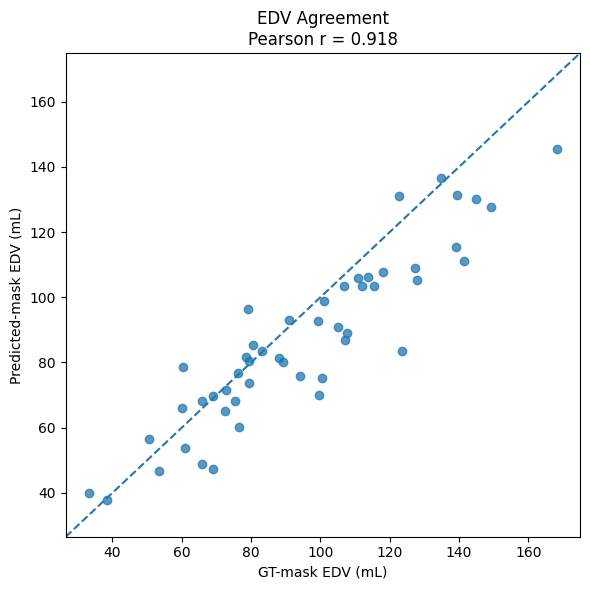

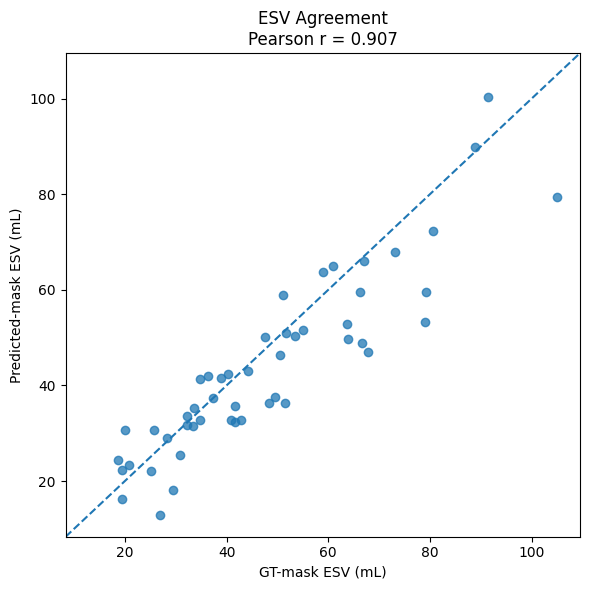

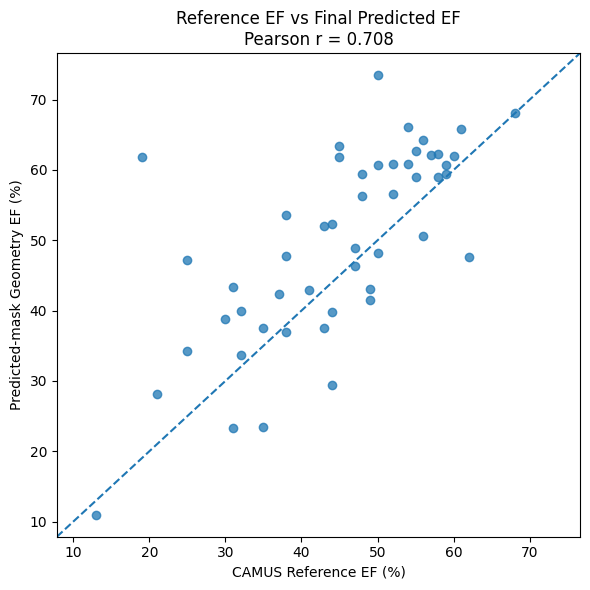


✓ Agreement plots saved to:
/content/drive/MyDrive/CAMUS_FINAL/phase2_quantitative/phase2B_final_evaluation/plots


In [ ]:
# ================================================================
# PHASE 2B — CELL 27
# AGREEMENT SCATTER PLOTS
# ================================================================

def agreement_scatter_plot(
    reference,
    estimate,
    xlabel,
    ylabel,
    title,
    save_path
):
    reference = np.asarray(
        reference,
        dtype=float
    )

    estimate = np.asarray(
        estimate,
        dtype=float
    )

    valid = (
        np.isfinite(reference)
        &
        np.isfinite(estimate)
    )

    reference = reference[valid]
    estimate = estimate[valid]

    correlation = pearsonr(
        reference,
        estimate
    ).statistic

    minimum = min(
        reference.min(),
        estimate.min()
    )

    maximum = max(
        reference.max(),
        estimate.max()
    )

    padding = (
        maximum - minimum
    ) * 0.05

    lower = minimum - padding
    upper = maximum + padding

    plt.figure(
        figsize=(6, 6)
    )

    plt.scatter(
        reference,
        estimate,
        alpha=0.75
    )

    # Identity line only — NOT a fitted/calibration line
    plt.plot(
        [lower, upper],
        [lower, upper],
        linestyle="--"
    )

    plt.xlim(
        lower,
        upper
    )

    plt.ylim(
        lower,
        upper
    )

    plt.xlabel(
        xlabel
    )

    plt.ylabel(
        ylabel
    )

    plt.title(
        f"{title}\nPearson r = {correlation:.3f}"
    )

    plt.tight_layout()

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()


# ------------------------------------------------
# EDV
# ------------------------------------------------

agreement_scatter_plot(

    test_measurements_df[
        "ED_GT_volume_ml"
    ],

    test_measurements_df[
        "ED_PRED_volume_ml"
    ],

    "GT-mask EDV (mL)",

    "Predicted-mask EDV (mL)",

    "EDV Agreement",

    P2B_PLOT_DIR /
    "agreement_EDV_GT_vs_PRED.png"
)


# ------------------------------------------------
# ESV
# ------------------------------------------------

agreement_scatter_plot(

    test_measurements_df[
        "ES_GT_volume_ml"
    ],

    test_measurements_df[
        "ES_PRED_volume_ml"
    ],

    "GT-mask ESV (mL)",

    "Predicted-mask ESV (mL)",

    "ESV Agreement",

    P2B_PLOT_DIR /
    "agreement_ESV_GT_vs_PRED.png"
)


# ------------------------------------------------
# Reference EF vs final predicted EF
# ------------------------------------------------

agreement_scatter_plot(

    test_measurements_df[
        "reference_EF_pct"
    ],

    test_measurements_df[
        "PRED_EF_pct"
    ],

    "CAMUS Reference EF (%)",

    "Predicted-mask Geometry EF (%)",

    "Reference EF vs Final Predicted EF",

    P2B_PLOT_DIR /
    "agreement_reference_vs_predicted_EF.png"
)


print(
    "\n✓ Agreement plots saved to:"
)

print(
    P2B_PLOT_DIR
)

In [ ]:
# ================================================================
# PHASE 2B — CELL 28
# PAIRED ED VS ES STATISTICAL ERROR ANALYSIS
# ================================================================

from scipy.stats import wilcoxon


# ------------------------------------------------
# Patient-level absolute relative AREA errors
# ------------------------------------------------

ed_area_gt = (
    test_measurements_df[
        "ED_GT_area_mm2"
    ].to_numpy(dtype=float)
)

ed_area_pred = (
    test_measurements_df[
        "ED_PRED_area_mm2"
    ].to_numpy(dtype=float)
)

es_area_gt = (
    test_measurements_df[
        "ES_GT_area_mm2"
    ].to_numpy(dtype=float)
)

es_area_pred = (
    test_measurements_df[
        "ES_PRED_area_mm2"
    ].to_numpy(dtype=float)
)


ed_area_abs_relative_error = (
    np.abs(
        ed_area_pred - ed_area_gt
    )
    /
    ed_area_gt
    *
    100.0
)

es_area_abs_relative_error = (
    np.abs(
        es_area_pred - es_area_gt
    )
    /
    es_area_gt
    *
    100.0
)


# ------------------------------------------------
# Patient-level absolute relative VOLUME errors
# ED volume = EDV
# ES volume = ESV
# ------------------------------------------------

edv_gt = (
    test_measurements_df[
        "ED_GT_volume_ml"
    ].to_numpy(dtype=float)
)

edv_pred = (
    test_measurements_df[
        "ED_PRED_volume_ml"
    ].to_numpy(dtype=float)
)

esv_gt = (
    test_measurements_df[
        "ES_GT_volume_ml"
    ].to_numpy(dtype=float)
)

esv_pred = (
    test_measurements_df[
        "ES_PRED_volume_ml"
    ].to_numpy(dtype=float)
)


edv_abs_relative_error = (
    np.abs(
        edv_pred - edv_gt
    )
    /
    edv_gt
    *
    100.0
)

esv_abs_relative_error = (
    np.abs(
        esv_pred - esv_gt
    )
    /
    esv_gt
    *
    100.0
)


# ------------------------------------------------
# Wilcoxon paired tests
#
# Alternative = "greater":
# tests the predefined question of whether
# ES error is greater than ED error.
# ------------------------------------------------

area_test = wilcoxon(
    es_area_abs_relative_error,
    ed_area_abs_relative_error,
    alternative="greater"
)

volume_test = wilcoxon(
    esv_abs_relative_error,
    edv_abs_relative_error,
    alternative="greater"
)


# ------------------------------------------------
# Paired differences
# Positive value = ES error > ED error
# ------------------------------------------------

area_difference = (
    es_area_abs_relative_error
    -
    ed_area_abs_relative_error
)

volume_difference = (
    esv_abs_relative_error
    -
    edv_abs_relative_error
)


# ------------------------------------------------
# Descriptive paired results
# ------------------------------------------------

statistical_records = [

    {
        "comparison":
            "ES vs ED area absolute relative error",

        "n":
            len(area_difference),

        "ED_mean_abs_relative_error_pct":
            float(
                np.mean(
                    ed_area_abs_relative_error
                )
            ),

        "ES_mean_abs_relative_error_pct":
            float(
                np.mean(
                    es_area_abs_relative_error
                )
            ),

        "median_paired_difference_ES_minus_ED_pct":
            float(
                np.median(
                    area_difference
                )
            ),

        "ES_error_greater_patients":
            int(
                np.sum(
                    area_difference > 0
                )
            ),

        "ED_error_greater_patients":
            int(
                np.sum(
                    area_difference < 0
                )
            ),

        "wilcoxon_statistic":
            float(
                area_test.statistic
            ),

        "p_value_one_sided":
            float(
                area_test.pvalue
            )
    },

    {
        "comparison":
            "ESV vs EDV absolute relative error",

        "n":
            len(volume_difference),

        "ED_mean_abs_relative_error_pct":
            float(
                np.mean(
                    edv_abs_relative_error
                )
            ),

        "ES_mean_abs_relative_error_pct":
            float(
                np.mean(
                    esv_abs_relative_error
                )
            ),

        "median_paired_difference_ES_minus_ED_pct":
            float(
                np.median(
                    volume_difference
                )
            ),

        "ES_error_greater_patients":
            int(
                np.sum(
                    volume_difference > 0
                )
            ),

        "ED_error_greater_patients":
            int(
                np.sum(
                    volume_difference < 0
                )
            ),

        "wilcoxon_statistic":
            float(
                volume_test.statistic
            ),

        "p_value_one_sided":
            float(
                volume_test.pvalue
            )
    }
]


ed_es_statistics_df = pd.DataFrame(
    statistical_records
)


print("=" * 70)
print("PAIRED ED VS ES ERROR ANALYSIS")
print("=" * 70)

display(
    ed_es_statistics_df.round(6)
)


# ------------------------------------------------
# Save
# ------------------------------------------------

ED_ES_STATISTICS_PATH = (
    P2B_TABLE_DIR /
    "final_test_ED_vs_ES_paired_statistics.csv"
)


ed_es_statistics_df.to_csv(
    ED_ES_STATISTICS_PATH,
    index=False
)


print("\nSaved:")
print(ED_ES_STATISTICS_PATH)

PAIRED ED VS ES ERROR ANALYSIS


,comparison,n,ED_mean_abs_relative_error_pct,ES_mean_abs_relative_error_pct,median_paired_difference_ES_minus_ED_pct,ES_error_greater_patients,ED_error_greater_patients,wilcoxon_statistic,p_value_one_sided
0,ES vs ED area absolute relative error,50,6.881699,9.482421,2.324142,35,15,897.0,0.005765
1,ESV vs EDV absolute relative error,50,11.876217,15.478090,2.293755,31,19,868.0,0.012750



Saved:
/content/drive/MyDrive/CAMUS_FINAL/phase2_quantitative/phase2B_final_evaluation/tables/final_test_ED_vs_ES_paired_statistics.csv


VISUAL FAILURE-CASE ANALYSIS


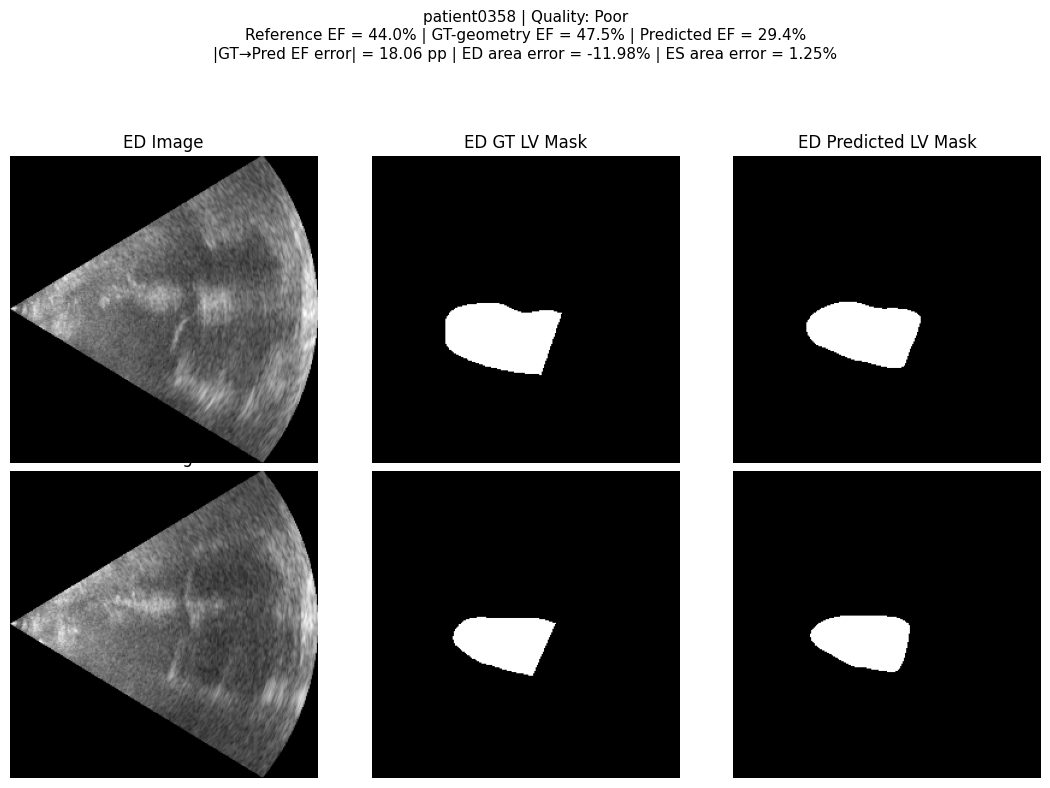

Saved: /content/drive/MyDrive/CAMUS_FINAL/phase2_quantitative/phase2B_final_evaluation/plots/failure_cases/patient0358_failure_case.png


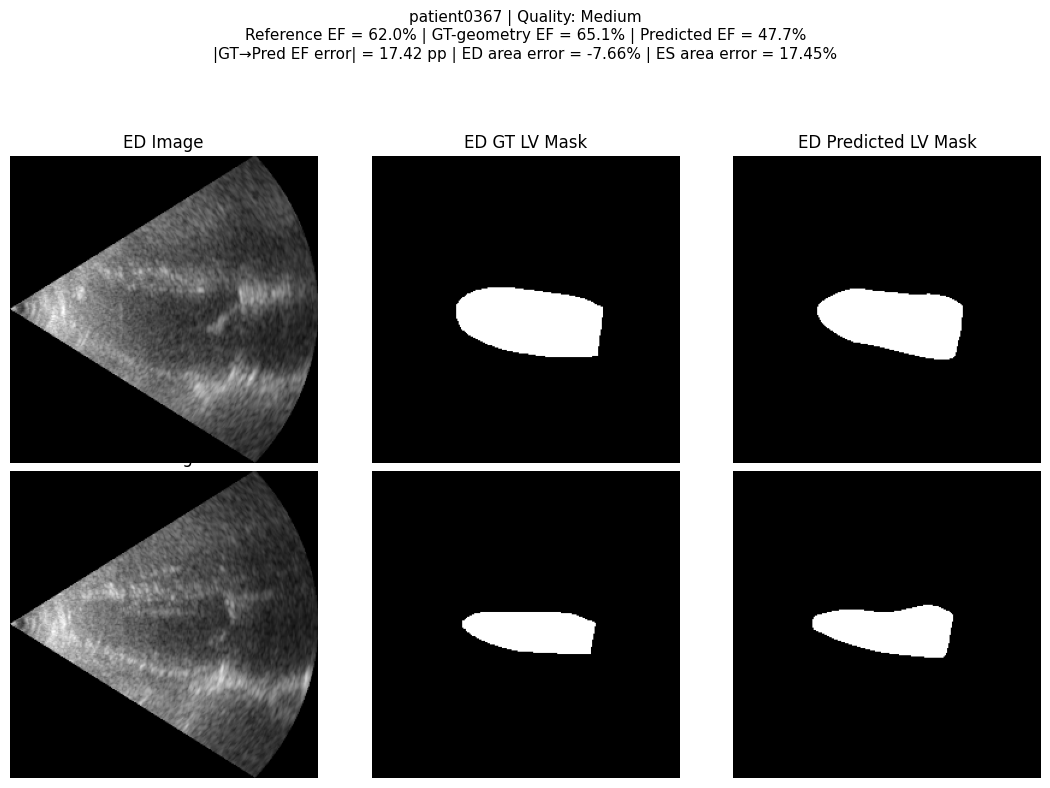

Saved: /content/drive/MyDrive/CAMUS_FINAL/phase2_quantitative/phase2B_final_evaluation/plots/failure_cases/patient0367_failure_case.png


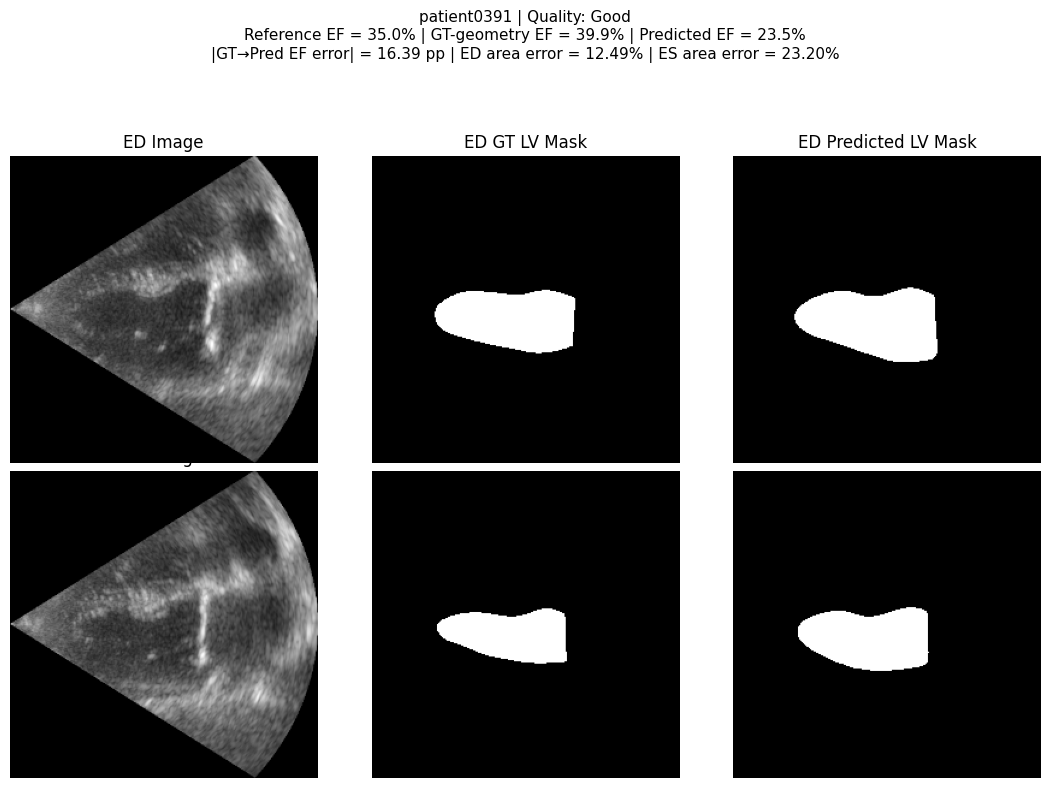

Saved: /content/drive/MyDrive/CAMUS_FINAL/phase2_quantitative/phase2B_final_evaluation/plots/failure_cases/patient0391_failure_case.png

✓ Three worst segmentation-induced EF cases visualized.


In [ ]:
# ================================================================
# PHASE 2B — CELL 29
# VISUAL FAILURE-CASE ANALYSIS
# ================================================================

# Select 3 largest segmentation-induced EF error cases
worst_three = (
    patient_error_df
    .sort_values(
        "GT_to_PRED_EF_abs_error_pp",
        ascending=False
    )
    .head(3)
    .copy()
)


FAILURE_CASE_DIR = (
    P2B_PLOT_DIR /
    "failure_cases"
)

FAILURE_CASE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


def get_prediction_for_visualization(
    patient_id,
    phase
):
    """
    Reconstruct the already-frozen prediction only for visualization.
    No parameters or pipeline decisions are changed.
    """

    patient_data = load_patient_data(
        patient_id
    )

    image = (
        patient_data[
            phase
        ]["image"]
    )

    native_gt_mask = (
        patient_data[
            phase
        ]["mask"]
    )


    processed_image, _ = (
        preprocess_for_segmentation(
            image,
            target_size=256
        )
    )


    resized_gt_mask = (
        preprocess_mask(
            native_gt_mask,
            target_size=256
        )
    )


    model_input = (
        processed_image[
            None,
            ...,
            None
        ]
    )


    probability = (
        frozen_segmentation_model(
            model_input,
            training=False
        )
        .numpy()[0, :, :, 0]
    )


    predicted_mask = (
        postprocess_prediction(
            probability,
            threshold=0.50
        )
    )


    return (
        processed_image,
        resized_gt_mask,
        predicted_mask
    )


print("=" * 70)
print("VISUAL FAILURE-CASE ANALYSIS")
print("=" * 70)


for _, row in worst_three.iterrows():

    pid = row[
        "patient_id"
    ]


    (
        ed_image,
        ed_gt,
        ed_pred
    ) = get_prediction_for_visualization(
        pid,
        "ED"
    )


    (
        es_image,
        es_gt,
        es_pred
    ) = get_prediction_for_visualization(
        pid,
        "ES"
    )


    fig, axes = plt.subplots(
        2,
        3,
        figsize=(11, 8)
    )


    # -------------------------
    # ED row
    # -------------------------

    axes[0, 0].imshow(
        ed_image,
        cmap="gray"
    )

    axes[0, 0].set_title(
        "ED Image"
    )


    axes[0, 1].imshow(
        ed_gt,
        cmap="gray"
    )

    axes[0, 1].set_title(
        "ED GT LV Mask"
    )


    axes[0, 2].imshow(
        ed_pred,
        cmap="gray"
    )

    axes[0, 2].set_title(
        "ED Predicted LV Mask"
    )


    # -------------------------
    # ES row
    # -------------------------

    axes[1, 0].imshow(
        es_image,
        cmap="gray"
    )

    axes[1, 0].set_title(
        "ES Image"
    )


    axes[1, 1].imshow(
        es_gt,
        cmap="gray"
    )

    axes[1, 1].set_title(
        "ES GT LV Mask"
    )


    axes[1, 2].imshow(
        es_pred,
        cmap="gray"
    )

    axes[1, 2].set_title(
        "ES Predicted LV Mask"
    )


    for ax in axes.flat:
        ax.axis("off")


    figure_title = (

        f"{pid} | Quality: "
        f"{row['image_quality']}\n"

        f"Reference EF = "
        f"{row['reference_EF_pct']:.1f}% | "

        f"GT-geometry EF = "
        f"{row['GT_EF_pct']:.1f}% | "

        f"Predicted EF = "
        f"{row['PRED_EF_pct']:.1f}%\n"

        f"|GT→Pred EF error| = "
        f"{row['GT_to_PRED_EF_abs_error_pp']:.2f} pp | "

        f"ED area error = "
        f"{row['ED_area_relative_error_pct']:.2f}% | "

        f"ES area error = "
        f"{row['ES_area_relative_error_pct']:.2f}%"
    )


    fig.suptitle(
        figure_title,
        fontsize=11
    )


    plt.tight_layout(
        rect=[0, 0, 1, 0.91]
    )


    save_path = (
        FAILURE_CASE_DIR /
        f"{pid}_failure_case.png"
    )


    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )


    plt.show()

    plt.close()


    print(
        f"Saved: {save_path}"
    )


print(
    "\n✓ Three worst segmentation-induced "
    "EF cases visualized."
)

In [ ]:
# ================================================================
# PHASE 2B — CELL 30
# FAILURE-CASE ANALYSIS RECORD
# ================================================================

failure_case_records = []

for _, row in worst_three.iterrows():

    failure_case_records.append({

        "patient_id":
            row["patient_id"],

        "image_quality":
            str(row["image_quality"]),

        "reference_EF_pct":
            float(row["reference_EF_pct"]),

        "GT_geometry_EF_pct":
            float(row["GT_EF_pct"]),

        "predicted_EF_pct":
            float(row["PRED_EF_pct"]),

        "GT_to_PRED_EF_abs_error_pp":
            float(
                row[
                    "GT_to_PRED_EF_abs_error_pp"
                ]
            ),

        "ED_area_relative_error_pct":
            float(
                row[
                    "ED_area_relative_error_pct"
                ]
            ),

        "ES_area_relative_error_pct":
            float(
                row[
                    "ES_area_relative_error_pct"
                ]
            )
    })


failure_analysis_record = {

    "analysis_type":
        "Locked-test qualitative failure analysis",

    "selection_rule":
        (
            "Three patients with the largest absolute "
            "GT-geometry to predicted-geometry EF error."
        ),

    "n_cases":
        3,

    "cases":
        failure_case_records,

    "observed_pattern":
        (
            "The three largest segmentation-induced EF errors "
            "showed asymmetric ED/ES segmentation errors. "
            "ED cavity area was underestimated in all three cases, "
            "while ES area was either only slightly different or "
            "substantially overestimated. This reduced the estimated "
            "ED-to-ES volume change and resulted in substantial "
            "underestimation of EF."
        ),

    "image_quality_observation":
        (
            "The three cases included Good, Medium, and Poor image "
            "quality labels. Therefore, large downstream errors were "
            "not confined to a single image-quality category."
        ),

    "interpretation_limit":
        (
            "These cases were selected because they had the largest "
            "errors and are used for qualitative failure analysis. "
            "They should not be interpreted as representative of "
            "all test patients."
        ),

    "pipeline_modified_after_analysis":
        False
}


FAILURE_RECORD_PATH = (
    P2B_CONFIG_DIR /
    "phase2B_failure_analysis_record.json"
)


with open(
    FAILURE_RECORD_PATH,
    "w"
) as f:

    json.dump(
        failure_analysis_record,
        f,
        indent=2
    )


print("=" * 70)
print("FAILURE ANALYSIS RECORDED")
print("=" * 70)

print("\nCases:")
for case in failure_case_records:
    print(
        case["patient_id"],
        "| Quality:",
        case["image_quality"],
        "| EF error:",
        f"{case['GT_to_PRED_EF_abs_error_pp']:.2f} pp"
    )

print("\nPipeline modified: NO")
print("\nSaved:")
print(FAILURE_RECORD_PATH)

FAILURE ANALYSIS RECORDED

Cases:
patient0358 | Quality: Poor | EF error: 18.06 pp
patient0367 | Quality: Medium | EF error: 17.42 pp
patient0391 | Quality: Good | EF error: 16.39 pp

Pipeline modified: NO

Saved:
/content/drive/MyDrive/CAMUS_FINAL/phase2_quantitative/phase2B_final_evaluation/configs/phase2B_failure_analysis_record.json


In [ ]:
# ================================================================
# PHASE 2 — CELL 31
# FINAL CONSOLIDATED PHASE 2 RECORD
# ================================================================

FINAL_PHASE2_RECORD_PATH = (
    PHASE2_DIR /
    "PHASE2_FINAL_RECORD.json"
)


final_phase2_record = {

    # ============================================================
    # GENERAL
    # ============================================================

    "phase":
        "Phase 2 — LV Quantitative Analysis",

    "status":
        "COMPLETE_AND_FROZEN",

    "project_scope":
        (
            "Assistive, non-diagnostic quantitative analysis "
            "of the left ventricle from A4C echocardiography."
        ),

    "dataset":
        "CAMUS",

    "evaluation_partition": {
        "partition": "test",
        "n_patients": 50,
        "n_frames": 100,
        "ED_frames": 50,
        "ES_frames": 50
    },

    "test_partition_note":
        (
            "The test partition was excluded from the clean "
            "Phase 1A-1D model-selection experiments and from "
            "Phase 2A quantitative-method selection. However, "
            "because this partition had historical pilot exposure, "
            "it is not described as a pristine external test set."
        ),


    # ============================================================
    # FROZEN SEGMENTATION PIPELINE
    # ============================================================

    "segmentation_pipeline": {

        "model_path":
            str(FINAL_MODEL_PATH),

        "model_sha256":
            EXPECTED_MODEL_SHA256,

        "input_resolution":
            "256x256",

        "architecture":
            "Large U-Net",

        "trainable_parameters":
            7759521,

        "threshold":
            0.50,

        "postprocessing": [
            "largest connected component",
            "binary hole filling"
        ],

        "status":
            "FROZEN"
    },


    # ============================================================
    # FROZEN QUANTITATIVE PIPELINE
    # ============================================================

    "quantitative_pipeline": {

        "physical_measurement":
            (
                "Original NIfTI pixel spacing adjusted separately "
                "in x and y for stretch-resize scaling."
            ),

        "LV_area":
            "binary LV cavity area in mm^2",

        "long_axis_method":
            "PCA major axis",

        "long_axis_selection_partition":
            "validation",

        "volume_method":
            "single-plane A4C area-length",

        "volume_equation":
            "V = (8/(3*pi)) * A^2/L",

        "EDV":
            "ED area-length volume in mL",

        "ESV":
            "ES area-length volume in mL",

        "SV":
            "EDV - ESV",

        "EF":
            "(EDV - ESV) / EDV * 100",

        "reference_EF":
            "CAMUS Info_4CH.cfg EF",

        "status":
            "FROZEN"
    },


    # ============================================================
    # SANITY CHECKS
    # ============================================================

    "sanity_checks": {

        "all_GT_EDV_positive":
            True,

        "all_GT_ESV_positive":
            True,

        "all_PRED_EDV_positive":
            True,

        "all_PRED_ESV_positive":
            True,

        "GT_EF_within_0_100":
            True,

        "PRED_EF_within_0_100":
            True,

        "all_GT_EDV_greater_than_ESV":
            True,

        "all_PRED_EDV_greater_than_ESV":
            True,

        "failed_checks":
            0
    },


    # ============================================================
    # SEGMENTATION → MEASUREMENT PROPAGATION
    # ============================================================

    "segmentation_to_measurement_results": {

        "ED_area": {
            "MAE_mm2": 203.1518,
            "RMSE_mm2": 255.3348,
            "bias_mm2": -146.0928,
            "correlation": 0.9417,
            "relative_MAE_pct": 6.8817,
            "relative_bias_pct": -4.3253
        },

        "ES_area": {
            "MAE_mm2": 179.2046,
            "RMSE_mm2": 236.2640,
            "bias_mm2": -112.7997,
            "correlation": 0.9116,
            "relative_MAE_pct": 9.4824,
            "relative_bias_pct": -5.0406
        },

        "ED_length": {
            "MAE_mm": 2.7934,
            "RMSE_mm": 3.8407,
            "bias_mm": -0.9855,
            "correlation": 0.9166,
            "relative_MAE_pct": 3.4233,
            "relative_bias_pct": -1.0651
        },

        "ES_length": {
            "MAE_mm": 3.3978,
            "RMSE_mm": 4.9774,
            "bias_mm": -2.2619,
            "correlation": 0.8589,
            "relative_MAE_pct": 5.1209,
            "relative_bias_pct": -3.2663
        },

        "EDV": {
            "MAE_ml": 11.4050,
            "RMSE_ml": 14.6416,
            "bias_ml": -8.2335,
            "correlation": 0.9182,
            "relative_MAE_pct": 11.8762,
            "relative_bias_pct": -7.0275
        },

        "ESV": {
            "MAE_ml": 7.1756,
            "RMSE_ml": 9.5907,
            "bias_ml": -4.1211,
            "correlation": 0.9070,
            "relative_MAE_pct": 15.4781,
            "relative_bias_pct": -6.1185
        },

        "SV": {
            "MAE_ml": 7.9325,
            "RMSE_ml": 10.4450,
            "bias_ml": -4.1124,
            "correlation": 0.8761
        },

        "EF": {
            "MAE_percentage_points": 5.8940,
            "RMSE_percentage_points": 7.5615,
            "bias_percentage_points": 0.1038,
            "correlation": 0.8474
        }
    },


    # ============================================================
    # EF ERROR DECOMPOSITION
    # ============================================================

    "EF_error_decomposition": {

        "reference_to_GT_geometry": {

            "interpretation":
                "Geometry/reference-method disagreement",

            "MAE_pp":
                6.6676,

            "RMSE_pp":
                9.6954,

            "bias_pp":
                4.8100,

            "correlation":
                0.7994
        },

        "GT_geometry_to_predicted_geometry": {

            "interpretation":
                "Segmentation-induced downstream disagreement",

            "MAE_pp":
                5.8940,

            "RMSE_pp":
                7.5615,

            "bias_pp":
                0.1038,

            "correlation":
                0.8474
        },

        "reference_to_predicted_geometry": {

            "interpretation":
                "Total end-to-end disagreement",

            "MAE_pp":
                8.1906,

            "RMSE_pp":
                11.0241,

            "bias_pp":
                4.9139,

            "correlation":
                0.7083
        },

        "important_note":
            (
                "These error components are not additive because "
                "signed errors may interact or partially cancel."
            )
    },


    # ============================================================
    # BLAND-ALTMAN AGREEMENT
    # ============================================================

    "bland_altman": {

        "EDV_GT_vs_PRED": {
            "bias_ml": -8.2335,
            "lower_95_LOA_ml": -32.2046,
            "upper_95_LOA_ml": 15.7376
        },

        "ESV_GT_vs_PRED": {
            "bias_ml": -4.1211,
            "lower_95_LOA_ml": -21.2672,
            "upper_95_LOA_ml": 13.0251
        },

        "EF_GT_geometry_vs_PRED": {
            "bias_pp": 0.1038,
            "lower_95_LOA_pp": -14.8657,
            "upper_95_LOA_pp": 15.0734
        },

        "EF_reference_vs_GT_geometry": {
            "bias_pp": 4.8100,
            "lower_95_LOA_pp": -11.8571,
            "upper_95_LOA_pp": 21.4771
        },

        "EF_reference_vs_PRED": {
            "bias_pp": 4.9139,
            "lower_95_LOA_pp": -14.6246,
            "upper_95_LOA_pp": 24.4523
        }
    },


    # ============================================================
    # IMAGE QUALITY SUBGROUPS
    # ============================================================

    "image_quality_analysis": {

        "Good": {
            "n": 30,
            "GT_to_PRED_EF_MAE_pp": 5.0287,
            "GT_to_PRED_EF_bias_pp": -1.1799,
            "Reference_to_PRED_EF_MAE_pp": 7.3117,
            "Reference_to_PRED_EF_bias_pp": 5.2960
        },

        "Medium": {
            "n": 13,
            "GT_to_PRED_EF_MAE_pp": 6.0277,
            "GT_to_PRED_EF_bias_pp": 2.5894,
            "Reference_to_PRED_EF_MAE_pp": 9.7344,
            "Reference_to_PRED_EF_bias_pp": 6.4258
        },

        "Poor": {
            "n": 7,
            "GT_to_PRED_EF_MAE_pp": 9.3545,
            "GT_to_PRED_EF_bias_pp": 0.9895,
            "Reference_to_PRED_EF_MAE_pp": 9.0902,
            "Reference_to_PRED_EF_bias_pp": 0.4682
        },

        "interpretation":
            (
                "Segmentation-induced EF error increased "
                "descriptively from Good to Medium to Poor image "
                "quality. The Poor subgroup contained only seven "
                "patients, so this analysis is considered descriptive "
                "rather than definitive."
            )
    },


    # ============================================================
    # ED VS ES PAIRED ANALYSIS
    # ============================================================

    "paired_ED_vs_ES_analysis": {

        "area": {

            "ED_mean_absolute_relative_error_pct":
                6.881699,

            "ES_mean_absolute_relative_error_pct":
                9.482421,

            "median_paired_ES_minus_ED_difference_pp":
                2.324142,

            "ES_error_greater_n":
                35,

            "ED_error_greater_n":
                15,

            "n":
                50,

            "test":
                "one-sided paired Wilcoxon signed-rank",

            "alternative":
                "ES absolute relative error > ED absolute relative error",

            "wilcoxon_statistic":
                897.0,

            "p_value":
                0.005765
        },

        "volume": {

            "EDV_mean_absolute_relative_error_pct":
                11.876217,

            "ESV_mean_absolute_relative_error_pct":
                15.478090,

            "median_paired_ES_minus_ED_difference_pp":
                2.293755,

            "ES_error_greater_n":
                31,

            "ED_error_greater_n":
                19,

            "n":
                50,

            "test":
                "one-sided paired Wilcoxon signed-rank",

            "alternative":
                "ESV absolute relative error > EDV absolute relative error",

            "wilcoxon_statistic":
                868.0,

            "p_value":
                0.012750
        },

        "interpretation":
            (
                "Within this 50-patient evaluation sample, "
                "ES-related area and volume errors were greater "
                "than the corresponding ED errors under the "
                "predefined paired analysis."
            )
    },


    # ============================================================
    # FAILURE-CASE ANALYSIS
    # ============================================================

    "failure_case_analysis": {

        "selection":
            (
                "Three patients with the largest absolute "
                "GT-geometry to predicted-geometry EF disagreement."
            ),

        "cases": [

            {
                "patient_id": "patient0358",
                "image_quality": "Poor",
                "reference_EF_pct": 44.0,
                "GT_geometry_EF_pct": 47.5,
                "predicted_EF_pct": 29.4,
                "GT_to_PRED_EF_error_pp": 18.06,
                "ED_area_relative_error_pct": -11.98,
                "ES_area_relative_error_pct": 1.25
            },

            {
                "patient_id": "patient0367",
                "image_quality": "Medium",
                "reference_EF_pct": 62.0,
                "GT_geometry_EF_pct": 65.1,
                "predicted_EF_pct": 47.7,
                "GT_to_PRED_EF_error_pp": 17.42,
                "ED_area_relative_error_pct": -7.66,
                "ES_area_relative_error_pct": 17.45
            },

            {
                "patient_id": "patient0391",
                "image_quality": "Good",
                "reference_EF_pct": 35.0,
                "GT_geometry_EF_pct": 39.9,
                "predicted_EF_pct": 23.5,
                "GT_to_PRED_EF_error_pp": 16.39,
                "ED_area_relative_error_pct": -12.49,
                "ES_area_relative_error_pct": 23.20
            }
        ],

        "observed_pattern":
            (
                "All three high-error cases showed ED cavity "
                "underestimation, while ES was either only slightly "
                "different or substantially overestimated. This "
                "asymmetric ED/ES error reduced the estimated "
                "ED-to-ES volume change and produced substantial "
                "EF underestimation."
            ),

        "image_quality_observation":
            (
                "The three cases included one Good, one Medium, "
                "and one Poor quality scan, showing that large "
                "downstream errors were not confined to poor-quality "
                "images."
            ),

        "interpretation_limit":
            (
                "These cases were deliberately selected as the "
                "largest errors and are not representative samples "
                "of the entire evaluation cohort."
            )
    },


    # ============================================================
    # MAIN PHASE 2 FINDINGS
    # ============================================================

    "main_findings": [

        (
            "The frozen segmentation masks enabled extraction "
            "of physically scaled LV area, PCA long-axis length, "
            "EDV, ESV, SV and EF."
        ),

        (
            "ES measurements were more sensitive to segmentation "
            "error than ED measurements."
        ),

        (
            "ES area absolute relative error was 9.48% compared "
            "with 6.88% at ED."
        ),

        (
            "ESV absolute relative error was 15.48% compared "
            "with 11.88% for EDV."
        ),

        (
            "The paired ED/ES analysis supported greater ES-related "
            "error for both area and volume within this evaluation "
            "sample."
        ),

        (
            "Predicted masks showed systematic underestimation "
            "of LV area and area-length volume on average."
        ),

        (
            "GT-to-predicted EF bias was close to zero despite "
            "volume underestimation because ED and ES errors can "
            "partially cancel in the EF ratio."
        ),

        (
            "Near-zero mean EF bias did not imply patient-level "
            "agreement; GT-to-predicted EF 95% limits of agreement "
            "were approximately -14.87 to +15.07 percentage points."
        ),

        (
            "Ground-truth-mask geometry itself differed materially "
            "from CAMUS reference EF, indicating that total "
            "end-to-end EF disagreement cannot be attributed "
            "solely to segmentation."
        ),

        (
            "Failure analysis demonstrated that asymmetric ED/ES "
            "segmentation errors can propagate nonlinearly into "
            "large EF errors."
        )
    ],


    # ============================================================
    # LIMITATIONS
    # ============================================================

    "limitations": [

        (
            "The volume calculation uses a simplified single-plane "
            "A4C area-length approximation."
        ),

        (
            "GT-mask-derived geometric EDV, ESV and EF are internal "
            "geometric comparators and are not equivalent to direct "
            "clinical ground-truth measurements."
        ),

        (
            "CAMUS Info_4CH.cfg provides reference EF but does not "
            "provide corresponding reference EDV and ESV values "
            "for direct absolute volume validation."
        ),

        (
            "The Poor image-quality subgroup contains only seven "
            "patients."
        ),

        (
            "The final evaluation partition had historical pilot "
            "exposure and is therefore not considered a pristine "
            "external test set."
        ),

        (
            "CAMUS does not contain longitudinal repeated visits "
            "for these patients, so this phase does not validate "
            "true longitudinal change tracking."
        )
    ],


    # ============================================================
    # FREEZE / PROVENANCE
    # ============================================================

    "methodological_integrity": {

        "segmentation_model_changed_after_final_evaluation":
            False,

        "segmentation_threshold_changed":
            False,

        "postprocessing_changed":
            False,

        "geometry_method_changed_after_test":
            False,

        "bias_correction_applied":
            False,

        "EF_calibration_applied":
            False,

        "test_cases_removed":
            False,

        "post_test_tuning_performed":
            False
    },

    "phase2_frozen":
        True,

    "pipeline_changes_allowed":
        False,

    "next_phase":
        "Phase 3 — EF-related classification"
}


# ================================================================
# SAVE FINAL RECORD
# ================================================================

with open(
    FINAL_PHASE2_RECORD_PATH,
    "w"
) as f:

    json.dump(
        final_phase2_record,
        f,
        indent=2
    )


print("=" * 72)
print("PHASE 2 — FINAL CONSOLIDATED RECORD")
print("=" * 72)

print("\nStatus                         : COMPLETE AND FROZEN")
print("Evaluation patients            : 50")
print("Sanity checks                  : ALL PASSED")

print("\n--- Measurement propagation ---")
print("ED area relative MAE           : 6.8817%")
print("ES area relative MAE           : 9.4824%")
print("EDV relative MAE               : 11.8762%")
print("ESV relative MAE               : 15.4781%")

print("\n--- EF decomposition ---")
print("Reference → GT geometry MAE     : 6.6676 pp")
print("GT geometry → Predicted MAE     : 5.8940 pp")
print("Reference → Predicted MAE       : 8.1906 pp")

print("\n--- ED vs ES paired analysis ---")
print("Area Wilcoxon p                 : 0.005765")
print("Volume Wilcoxon p               : 0.012750")

print("\n--- Failure analysis ---")
print("Cases                           : 3")
print("Pipeline modified afterward     : NO")

print("\nPost-test tuning                 : NONE")
print("Phase 2 pipeline                : FROZEN")

print("\nSaved:")
print(FINAL_PHASE2_RECORD_PATH)

PHASE 2 — FINAL CONSOLIDATED RECORD

Status                         : COMPLETE AND FROZEN
Evaluation patients            : 50
Sanity checks                  : ALL PASSED

--- Measurement propagation ---
ED area relative MAE           : 6.8817%
ES area relative MAE           : 9.4824%
EDV relative MAE               : 11.8762%
ESV relative MAE               : 15.4781%

--- EF decomposition ---
Reference → GT geometry MAE     : 6.6676 pp
GT geometry → Predicted MAE     : 5.8940 pp
Reference → Predicted MAE       : 8.1906 pp

--- ED vs ES paired analysis ---
Area Wilcoxon p                 : 0.005765
Volume Wilcoxon p               : 0.012750

--- Failure analysis ---
Cases                           : 3
Pipeline modified afterward     : NO

Post-test tuning                 : NONE
Phase 2 pipeline                : FROZEN

Saved:
/content/drive/MyDrive/CAMUS_FINAL/phase2_quantitative/PHASE2_FINAL_RECORD.json


In [ ]:
# ================================================================
# PHASE 2 — CELL 32
# COMPLETION MARKER
# ================================================================

PHASE2_COMPLETION_PATH = (
    PHASE2_DIR /
    "PHASE2_COMPLETE.json"
)


phase2_completion = {

    "phase":
        "Phase 2 — LV Quantitative Analysis",

    "status":
        "COMPLETE",

    "phase2A":
        (
            "Quantitative measurement methodology developed "
            "and selected using validation data."
        ),

    "phase2B":
        (
            "Locked final quantitative evaluation completed "
            "on 50 patients."
        ),

    "final_pipeline":
        (
            "A4C image → frozen LV segmentation → "
            "physical LV area → PCA long-axis → "
            "single-plane area-length EDV/ESV → SV → EF"
        ),

    "segmentation_model_frozen":
        True,

    "quantitative_method_frozen":
        True,

    "post_test_tuning":
        False,

    "final_record":
        str(FINAL_PHASE2_RECORD_PATH),

    "next_phase":
        "Phase 3 — EF-related classification"
}


with open(
    PHASE2_COMPLETION_PATH,
    "w"
) as f:

    json.dump(
        phase2_completion,
        f,
        indent=2
    )


print("=" * 72)
print("PHASE 2 COMPLETE")
print("=" * 72)

print(
    "\nA4C ECHO"
    "\n   ↓"
    "\nFrozen LV Segmentation"
    "\n   ↓"
    "\nPhysical Area + PCA Long Axis"
    "\n   ↓"
    "\nEDV / ESV"
    "\n   ↓"
    "\nSV / EF"
)

print("\n✓ Phase 2A method development complete")
print("✓ Phase 2B locked evaluation complete")
print("✓ Agreement analysis complete")
print("✓ ED vs ES statistical analysis complete")
print("✓ Image-quality analysis complete")
print("✓ Failure-case analysis complete")
print("✓ No post-test tuning performed")
print("✓ Phase 2 frozen")

print("\nReady for Phase 3.")

PHASE 2 COMPLETE

A4C ECHO
   ↓
Frozen LV Segmentation
   ↓
Physical Area + PCA Long Axis
   ↓
EDV / ESV
   ↓
SV / EF

✓ Phase 2A method development complete
✓ Phase 2B locked evaluation complete
✓ Agreement analysis complete
✓ ED vs ES statistical analysis complete
✓ Image-quality analysis complete
✓ Failure-case analysis complete
✓ No post-test tuning performed
✓ Phase 2 frozen

Ready for Phase 3.
